In [44]:
import sys, sklearn, ipykernel
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
print(sys.version)
print(sys.executable)
print("Setup OK!")

print('test data cleaning')

print('hi')

# 1. Read the mapping file without skipping the blank rows between tables
IDS_mapping = pd.read_csv("IDs_mapping.csv", header=None,
                  names=["id", "description"], skip_blank_lines=False)

# 2. Split it into one dictionary per table
mappings = {}
current = None
for _, row in IDS_mapping.iterrows():
    if pd.isna(row["id"]):          # blank row: the next table starts
        current = None
    elif current is None:           # first row of a table = its name
        current = row["id"]
        mappings[current] = {}
    else:                           # normal row: code -> description
        mappings[current][int(row["id"])] = row["description"]

# 3. Replace the codes in the patient data with their descriptions
df = pd.read_csv("diabetic_data.csv", na_values=['?'])
for col, mapping in mappings.items():
    df[col] = df[col].map(mapping)


3.14.9 (v3.14.9:ead82c07db1, Oct 20 2026, 23:27:28) [Clang 21.0.0 (clang-2100.1.1.101)]
/Users/mrcalje/Downloads/Year 4/Block 2/ML/Project/.venv/bin/python
Setup OK!
test data cleaning
hi


/var/folders/t2/z2d0j1ns56l8gkc11rwm53pw0000gn/T/ipykernel_41427/2467756455.py:32: DtypeWarning: Columns (0: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("diabetic_data.csv", na_values=['?'])


### Duplicates
Here we check the number of duplicates.

I found in encounter_id 0 duplicates, so each row contains its own encounter with a person at a hospital for some treatment.
In patient_nbr I found 71518 unique values, so there are 71518 unique persons in the database.
For the rest the duplicates seemed fine

In [38]:
dup_counts = df.apply(lambda col: col.duplicated().sum())

# Missing values per column (count and percentage)
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df) * 100).round(2)

# Put it all in one table
summary = pd.DataFrame({
    "n_unique": df.nunique(),
    "n_duplicates": dup_counts,
    "n_missing": missing_counts,
    "pct_missing": missing_pct
}).sort_values("n_missing", ascending=False)

print(summary.to_string())

print(df.shape)

                          n_unique  n_duplicates  n_missing  pct_missing
weight                           9        101756      98569        96.86
max_glu_serum                    3        101762      96420        94.75
A1Cresult                        3        101762      84748        83.28
medical_specialty               72        101693      49949        49.08
payer_code                      17        101748      40256        39.56
admission_source_id             16        101749       6781         6.66
admission_type_id                7        101758       5291         5.20
discharge_disposition_id        25        101740       3691         3.63
race                             5        101760       2273         2.23
diag_3                         789        100976       1423         1.40
diag_2                         748        101017        358         0.35
diag_1                         716        101049         21         0.02
acarbose                         4        101762   

### Missing values

Here we check the missing and possible missing values in the dataset.
- Race has 2273 NaN and 1506 Other.
- Gender has 3 Unknown/Invalid values, which are not noted as missing values in python here.
- Weight has 98569 (96,8%) values, so should be dropped!
- Payer_code has 40256 (39,5%) NaN values
- medical_specialty has 49949 NaN values which is 49,1% of the dataset.
    - However the names should be checked, which are not good and which should be combined with an umbrella specialty like the two separate ones 'Orthopedics' and 'Orthopedics-Reconstructive'. Domain knowledge should be applied here.
- diag_1 has 21 missing values (0.02%)
- diag_2 has 358 missing values (0.35%)
- diag_3 has 1423 missing values (1.40%)
- max_glu_serum has 96420 (94.75%) missing values
- A1Cresult has 84748 (83.28%) missing values.
- Examide, citoglipton no missing values, glimepiride-pioglitazone, metformin-rosiglitazone, metformin-pioglitazone but only contains no.

All other columns do not contain missing values, '?' or other weird values


In [39]:
df = pd.read_csv("diabetic_data.csv", na_values="?")

pd.set_option("display.max_rows", None)   # show all rows, no "..."

cols_with_missing = df.columns

for col in cols_with_missing:
    print(f"\n=== {col} ({df[col].nunique()} unique values) ===")
    print(df[col].value_counts(dropna=False))

cols = ["diag_1", "diag_2", "diag_3"]
missing = df[cols].isnull().sum()
percent = (missing / len(df) * 100).round(2)

print(pd.DataFrame({"missing": missing, "percent": percent}))

print(df.shape)

/var/folders/t2/z2d0j1ns56l8gkc11rwm53pw0000gn/T/ipykernel_41427/2776093993.py:1: DtypeWarning: Columns (0: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("diabetic_data.csv", na_values="?")



=== encounter_id (101766 unique values) ===
encounter_id
2278392      1
149190       1
64410        1
500364       1
16680        1
35754        1
55842        1
63768        1
12522        1
15738        1
28236        1
36900        1
40926        1
42570        1
62256        1
73578        1
77076        1
84222        1
89682        1
148530       1
150006       1
150048       1
182796       1
183930       1
216156       1
221634       1
236316       1
248916       1
250872       1
252822       1
253380       1
253722       1
260166       1
293058       1
293118       1
325848       1
325866       1
326028       1
358776       1
377268       1
383430       1
419304       1
421194       1
449142       1
450210       1
464994       1
486156       1
498030       1
537834       1
544194       1
550098       1
584136       1
590346       1
591996       1
604188       1
623880       1
630342       1
654918       1
669954       1
676416       1
676422       1
679722       1
682494      

The code below shows that encounter_id and patient_nbr have only numeral values.

In [40]:
for col in ["encounter_id", "patient_nbr"]:
    values = df[col].astype(str).str.strip()
    non_numeric = df[pd.to_numeric(df[col], errors="coerce").isna()]
    
    print(f"{col}: {len(non_numeric)} non-numeric rows")
    if len(non_numeric) > 0:
        print(non_numeric[[col]].head(20))

    lengths = df[col].astype(str).str.len()
    counts = lengths[lengths <= 4].value_counts().sort_index()

    print(f"\n{col}:")
    for length in range(1, 5):
        print(f"  {length} digits: {counts.get(length, 0)}")

encounter_id: 0 non-numeric rows

encounter_id:
  1 digits: 0
  2 digits: 0
  3 digits: 0
  4 digits: 0
patient_nbr: 0 non-numeric rows

patient_nbr:
  1 digits: 0
  2 digits: 0
  3 digits: 6
  4 digits: 31


In [41]:
#Nateglinide
print(df['nateglinide'].value_counts(normalize= True))

#chlorpropamide
print(df['chlorpropamide'].value_counts(normalize=True)) #>99.9

#acetohexamide
print(df['acetohexamide'].value_counts(normalize=True)) #>99.9

#tolbutamide
print(df['tolbutamide'].value_counts(normalize=True)) #>99.9

#acarbose
print(df['acarbose'].value_counts(normalize=True)) 

#miglitol
print(df['miglitol'].value_counts(normalize=True)) #>99.9

#troglitazone
print(df['troglitazone'].value_counts(normalize=True)) #99.9

#tolazamide
print(df['tolazamide'].value_counts(normalize=True)) #>99.9

#glyburide-metformin
print(df['glyburide-metformin'].value_counts(normalize=True))

#glipizide-metformin
print(df['glipizide-metformin'].value_counts(normalize=True)) #>99.9

#glimepiride-pioglitazone
print(df['glimepiride-pioglitazone'].value_counts(normalize=True)) #>99.9

#metformin-rosiglitazone
print(df['metformin-rosiglitazone'].value_counts(normalize=True)) #>99.9

#metformin-pioglitazone
print(df['metformin-pioglitazone'].value_counts(normalize=True)) #>99.9



nateglinide
No        0.993092
Steady    0.006564
Up        0.000236
Down      0.000108
Name: proportion, dtype: float64
chlorpropamide
No        0.999155
Steady    0.000776
Up        0.000059
Down      0.000010
Name: proportion, dtype: float64
acetohexamide
No        0.99999
Steady    0.00001
Name: proportion, dtype: float64
tolbutamide
No        0.999774
Steady    0.000226
Name: proportion, dtype: float64
acarbose
No        0.996973
Steady    0.002899
Up        0.000098
Down      0.000029
Name: proportion, dtype: float64
miglitol
No        0.999627
Steady    0.000305
Down      0.000049
Up        0.000020
Name: proportion, dtype: float64
troglitazone
No        0.999971
Steady    0.000029
Name: proportion, dtype: float64
tolazamide
No        0.999617
Steady    0.000373
Up        0.000010
Name: proportion, dtype: float64
glyburide-metformin
No        0.993063
Steady    0.006800
Up        0.000079
Down      0.000059
Name: proportion, dtype: float64
glipizide-metformin
No        0.999872


# Visuals of univariate plots

Here we see that there is an outlier of 0 with num_lab_procedures, but that the variable is normally distributed

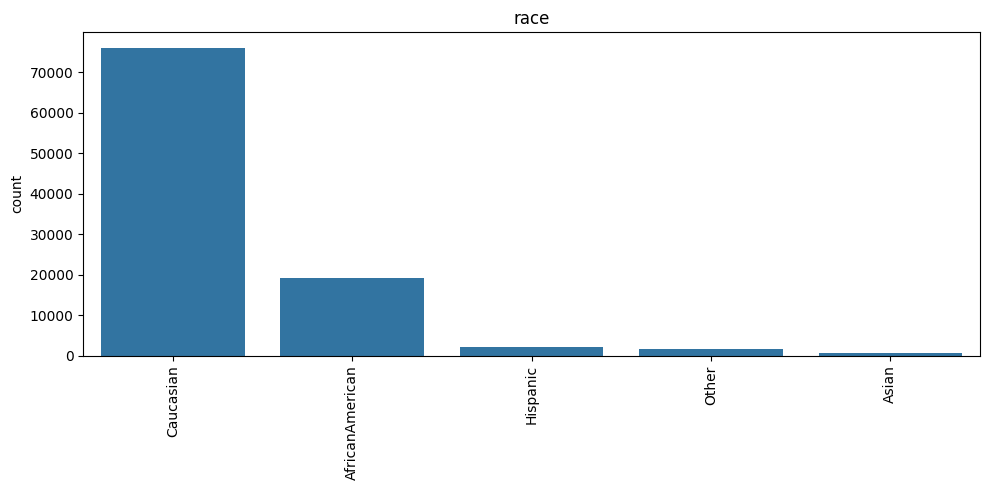

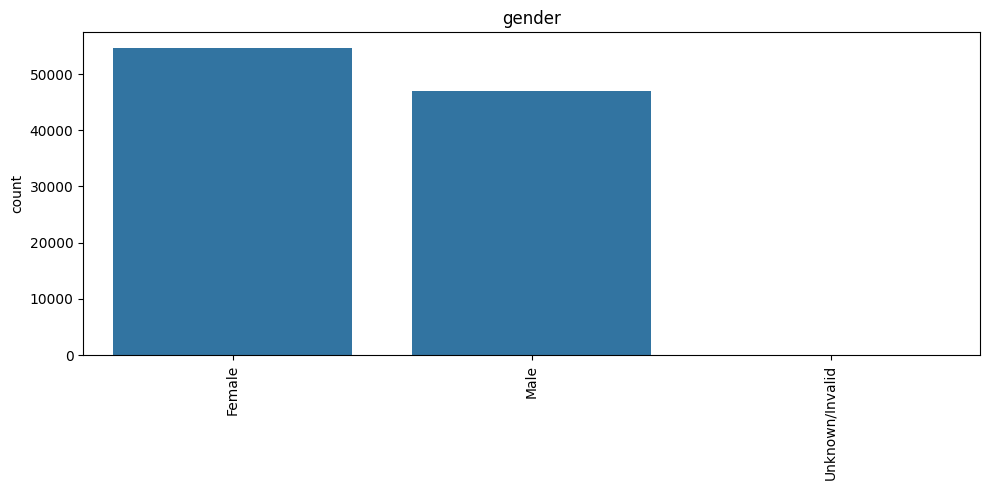

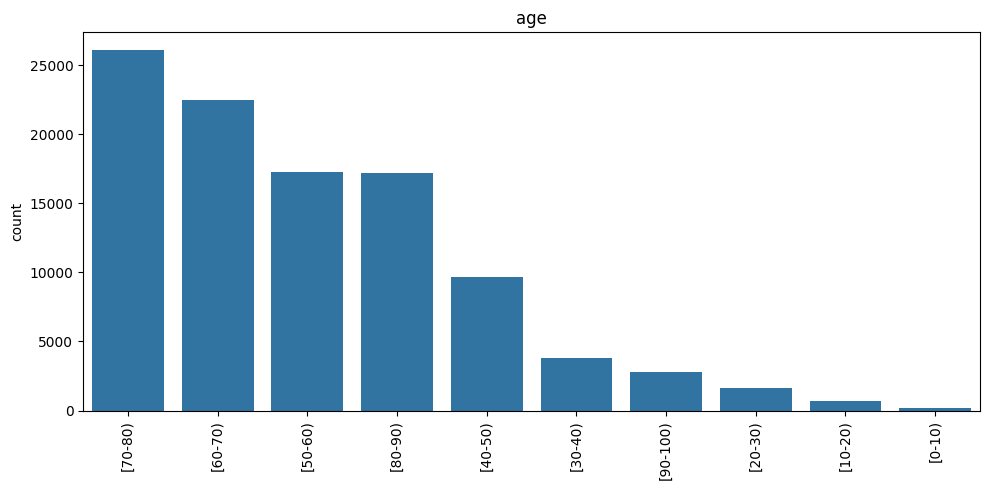

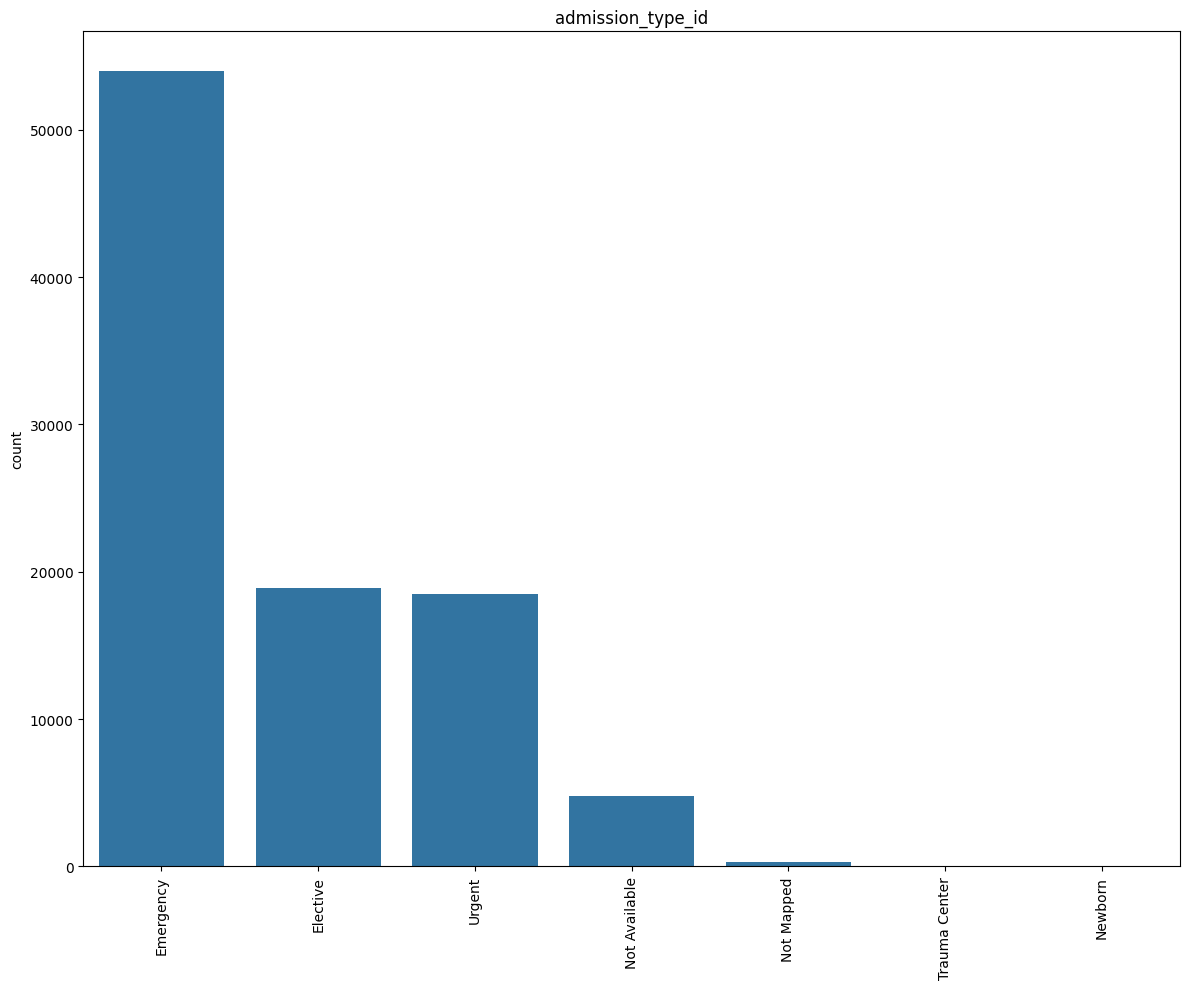

/var/folders/t2/z2d0j1ns56l8gkc11rwm53pw0000gn/T/ipykernel_41427/892955721.py:28: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


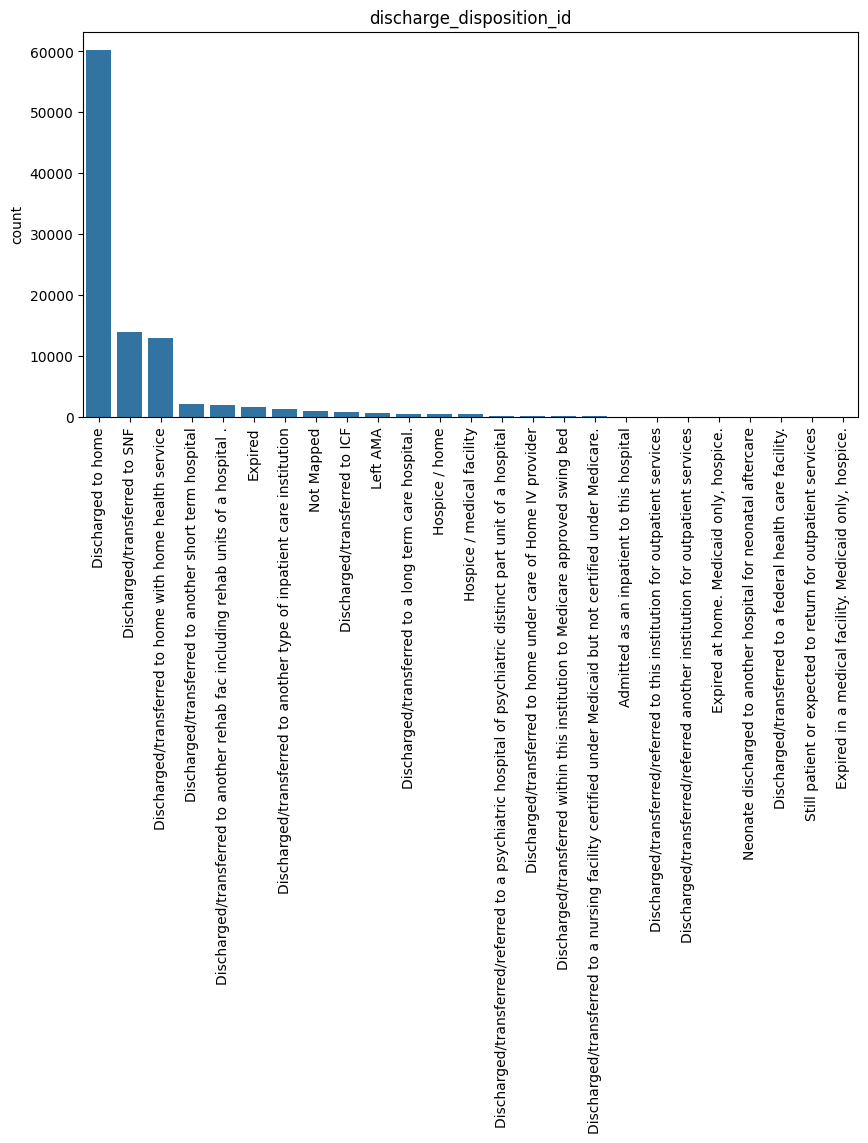

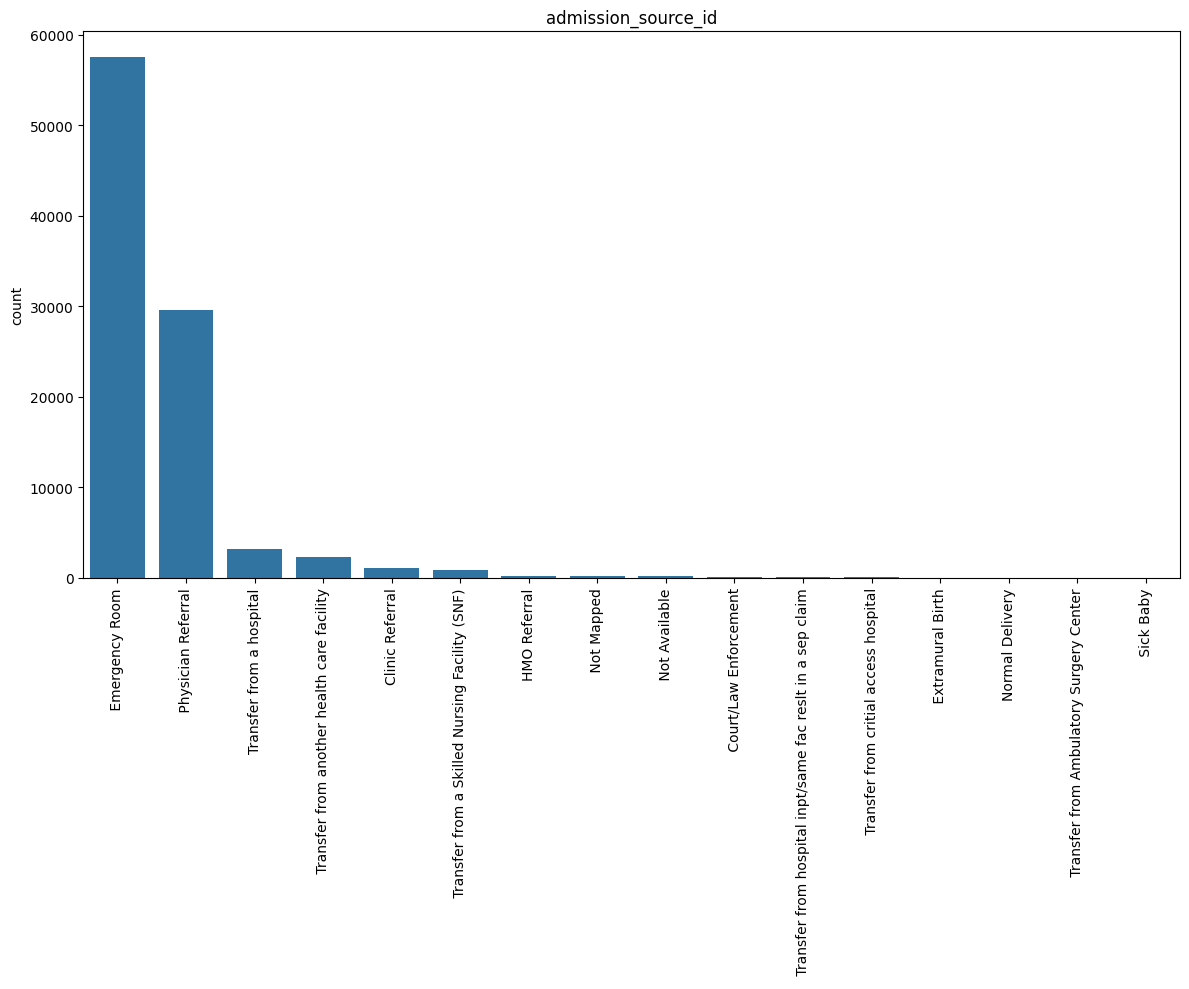

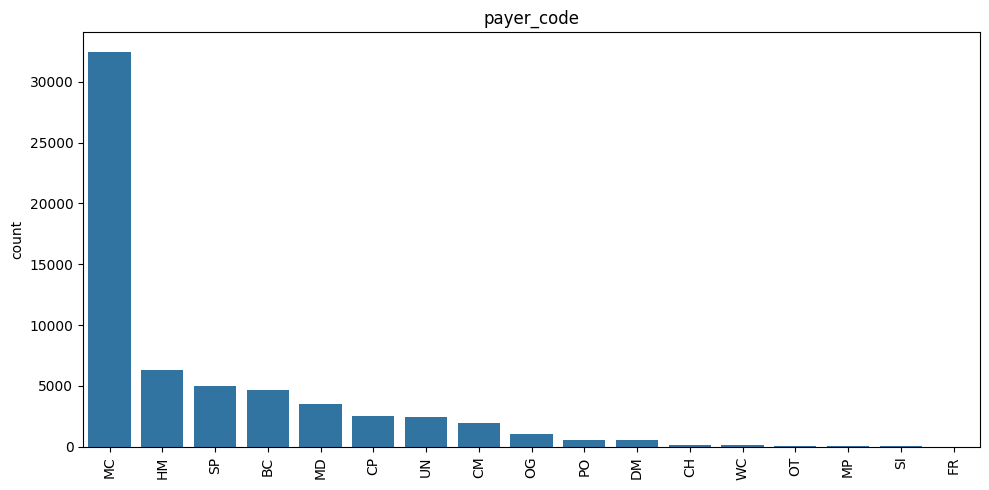

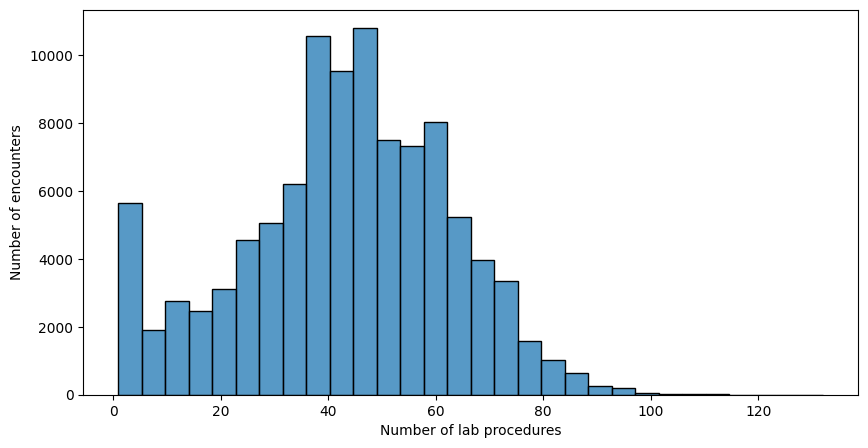

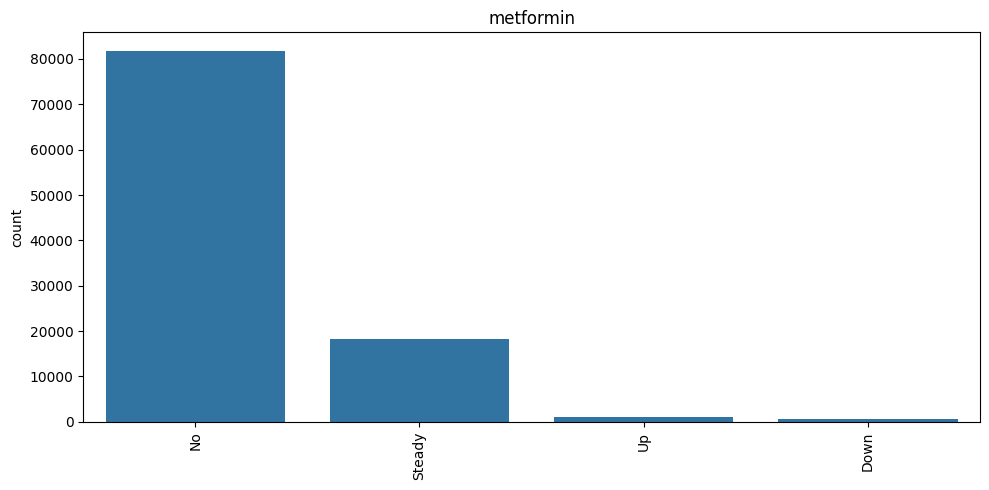

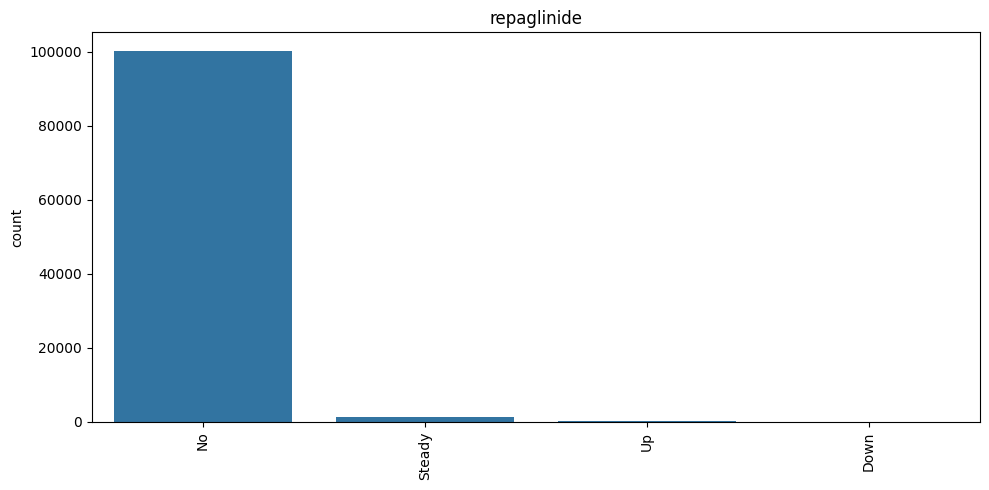

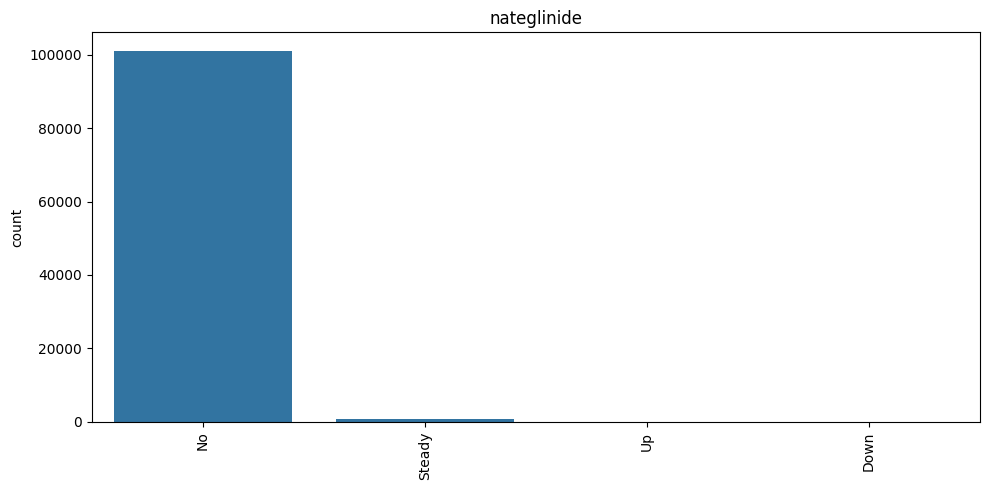

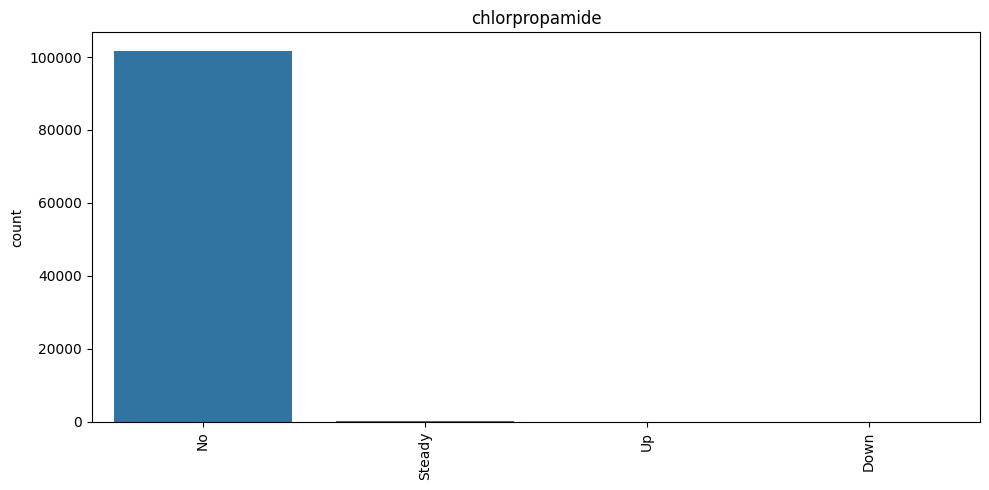

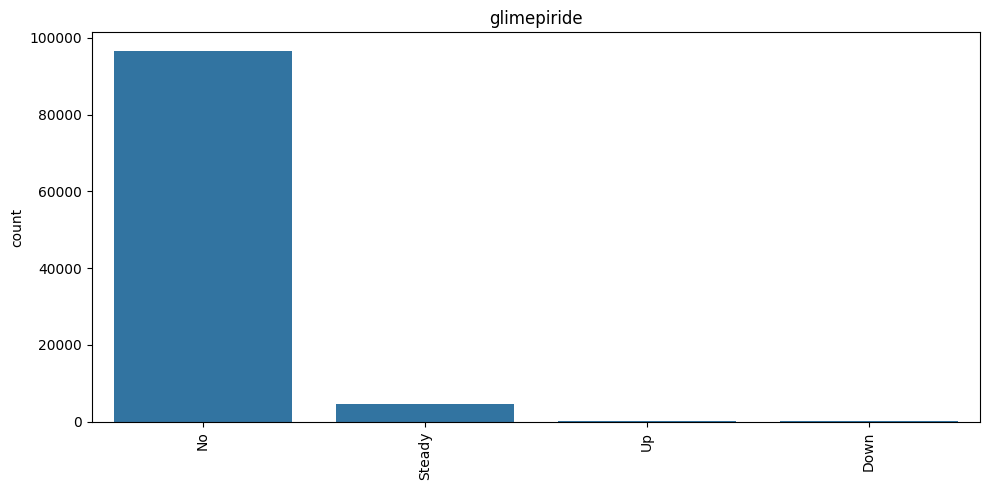

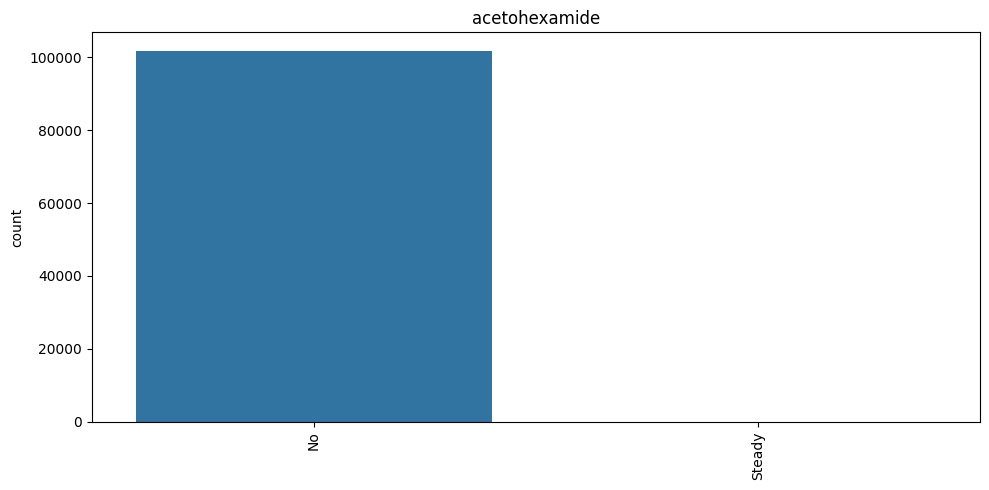

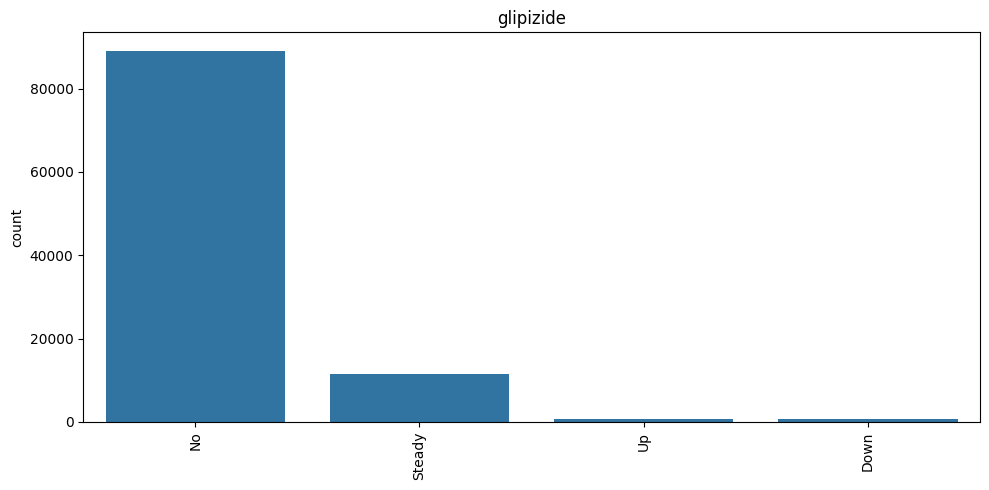

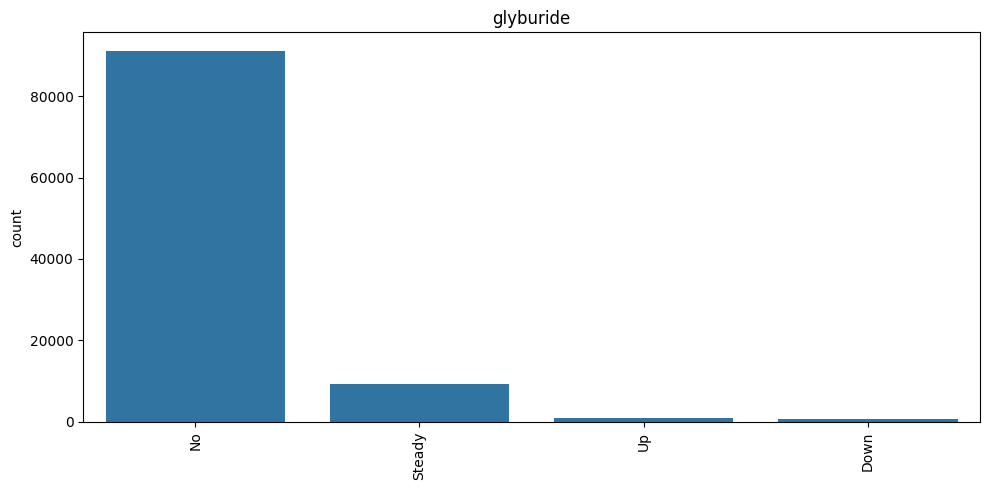

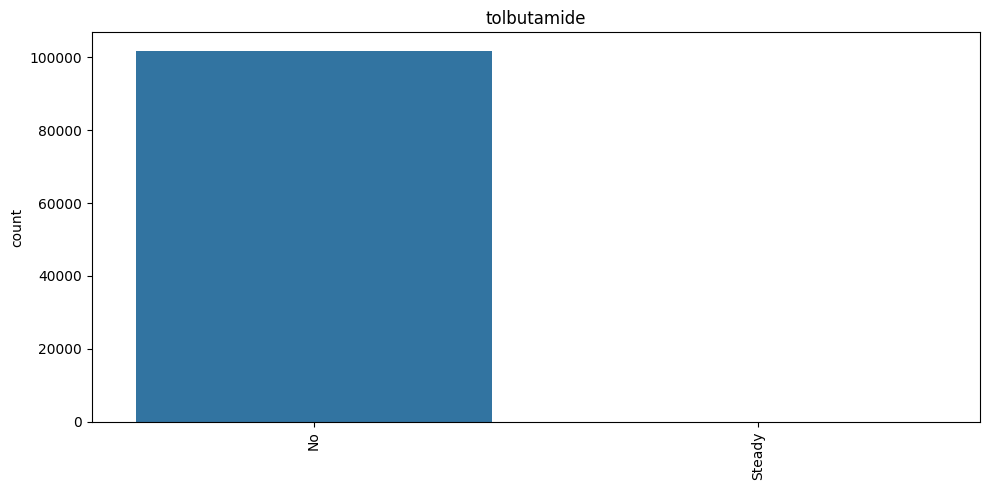

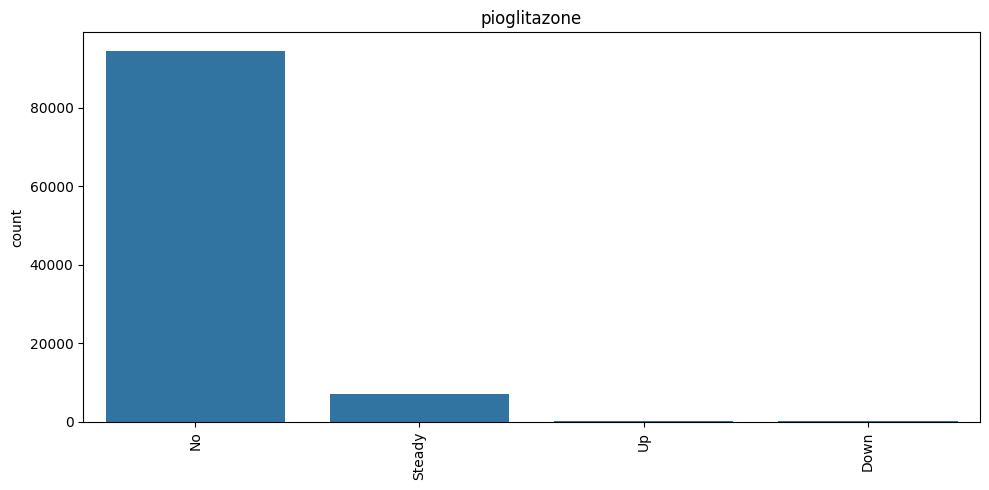

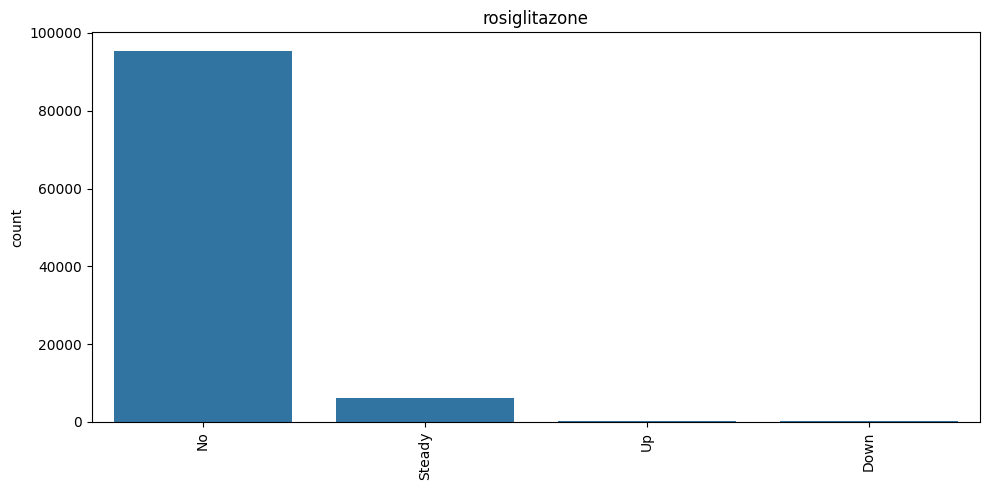

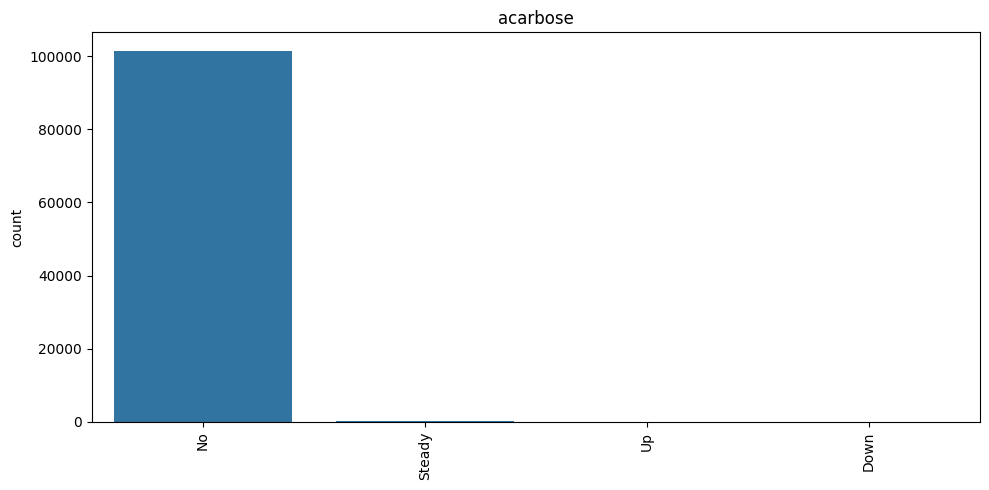

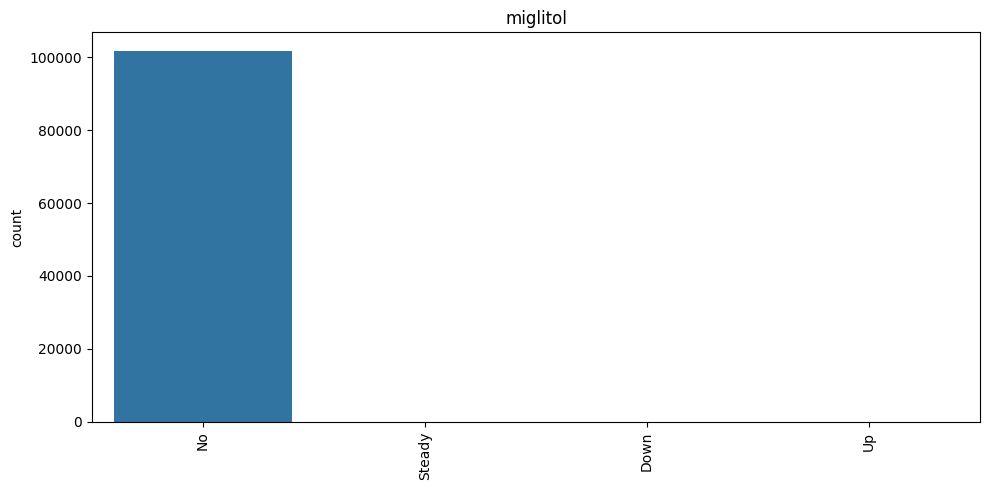

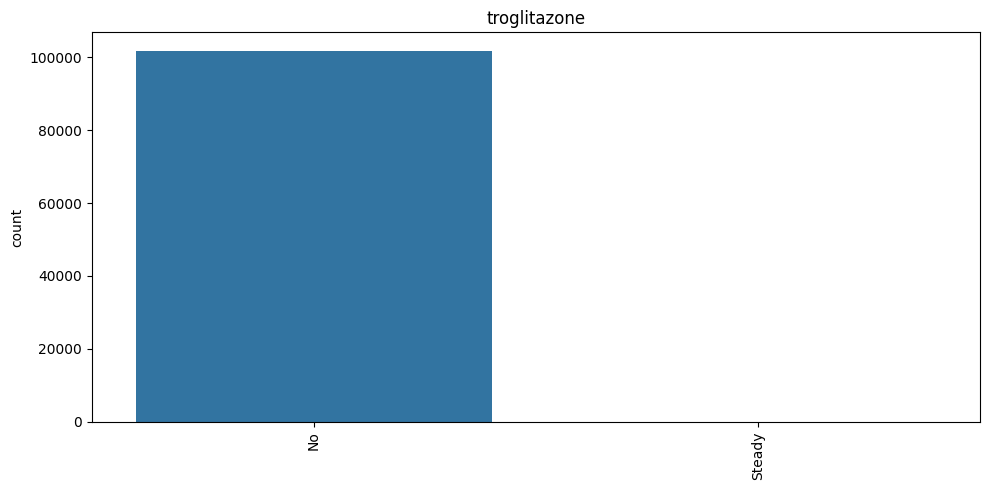

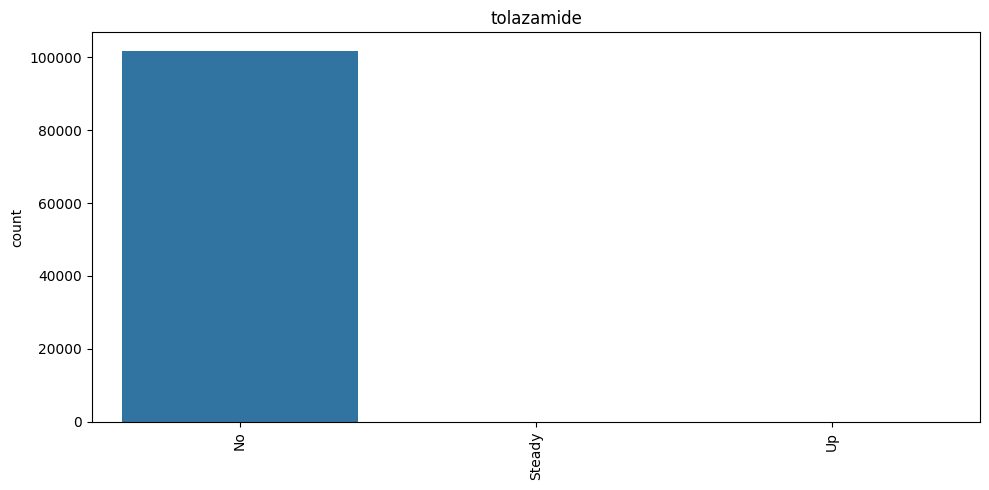

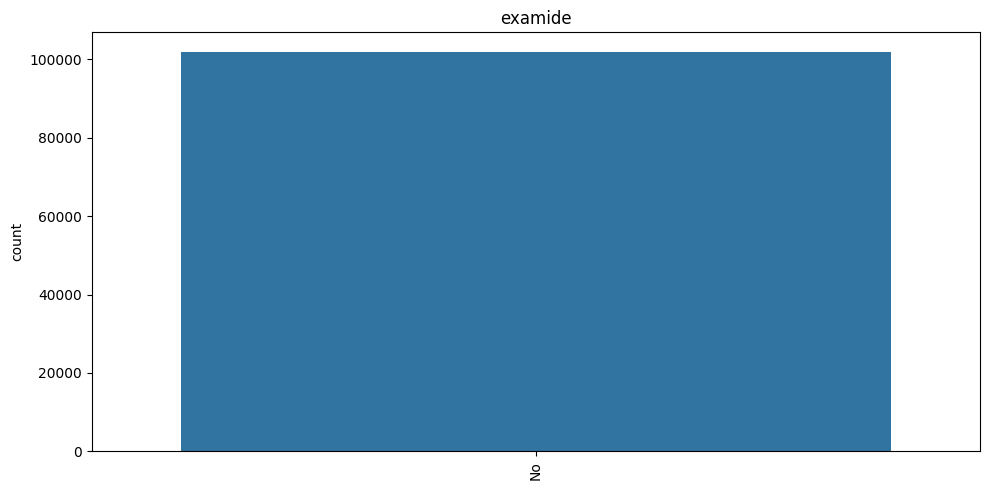

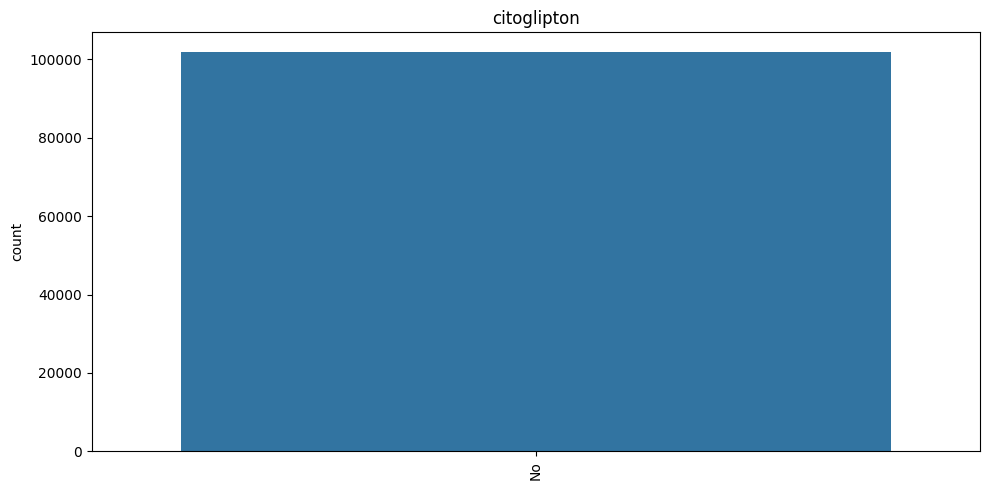

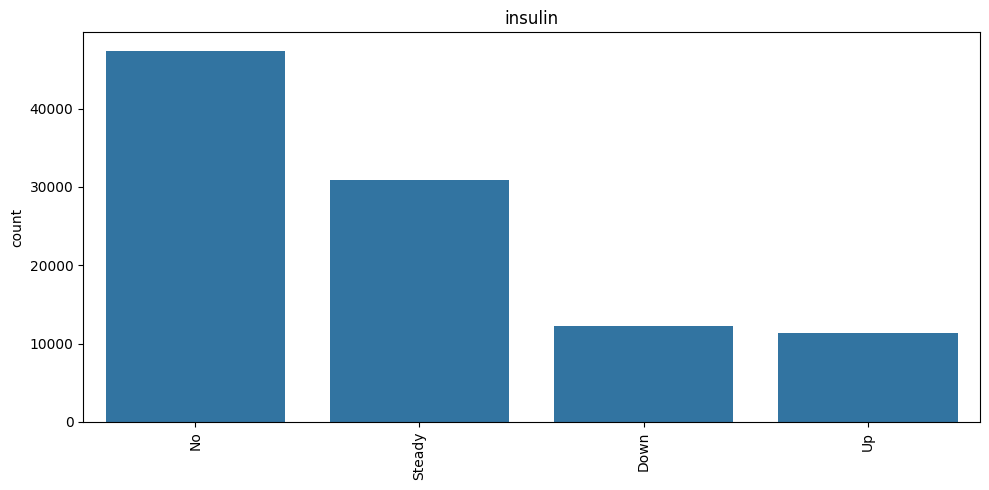

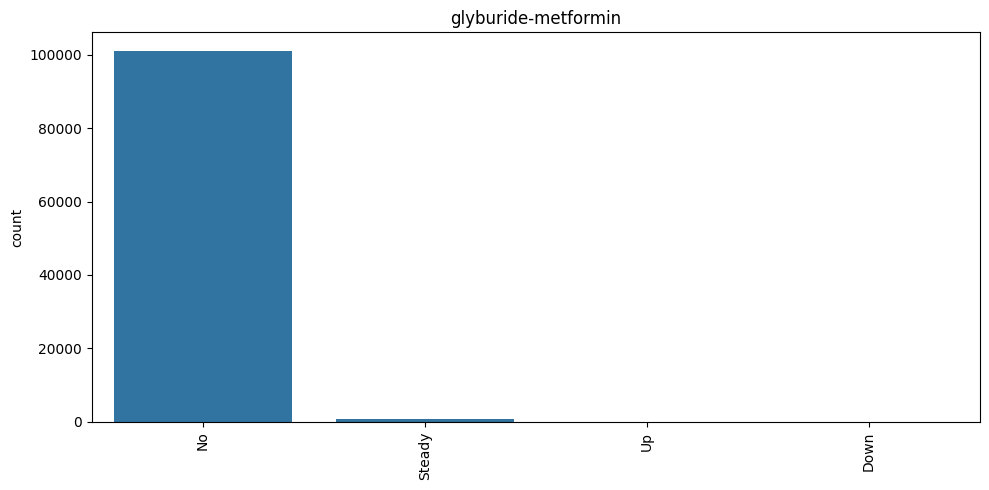

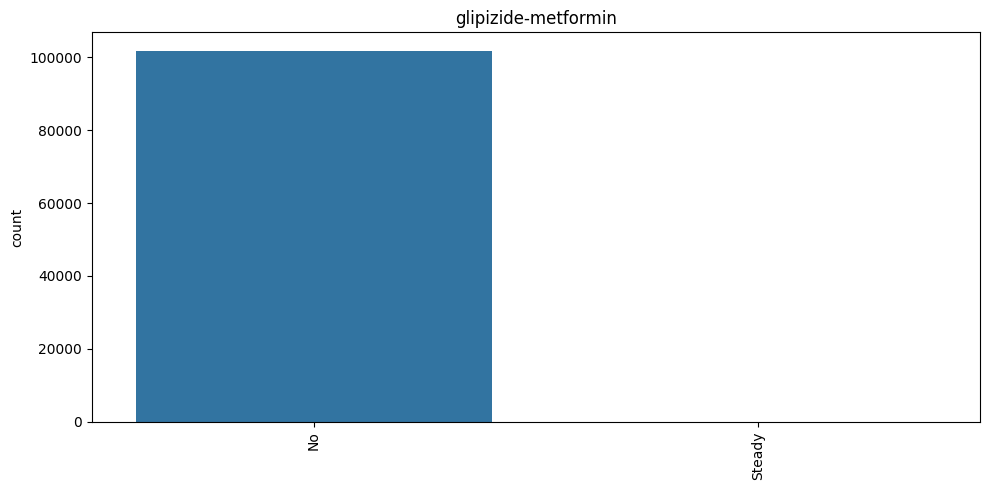

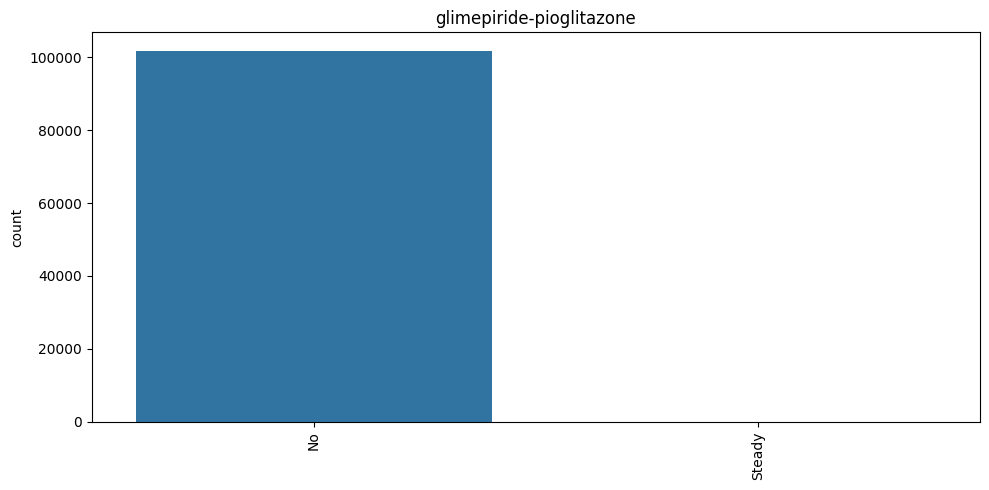

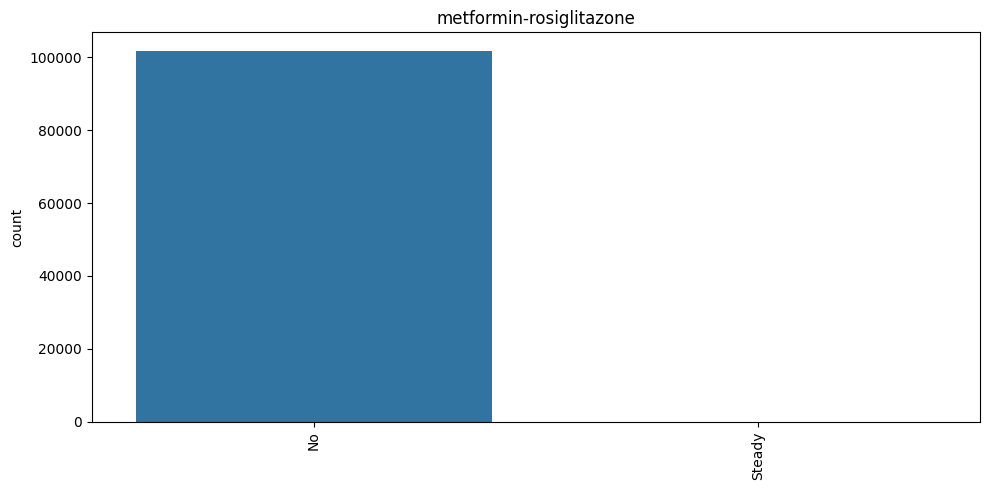

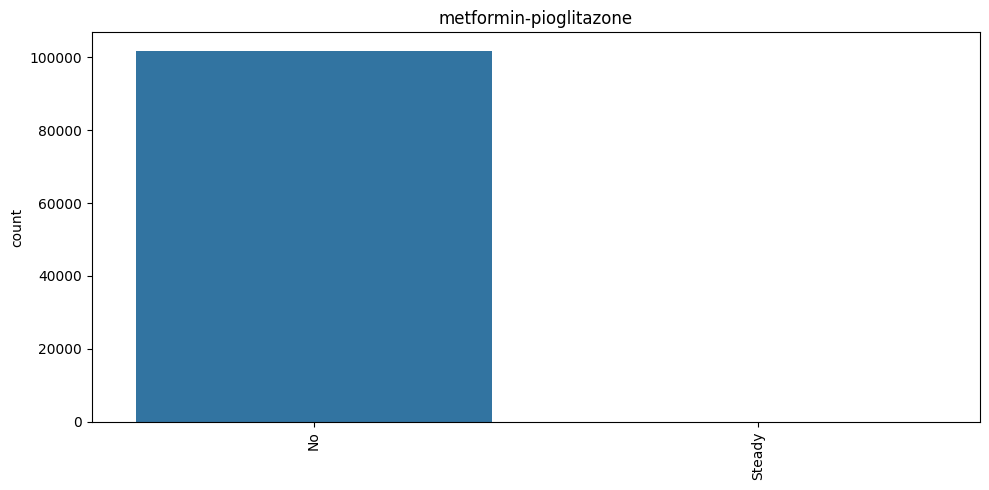

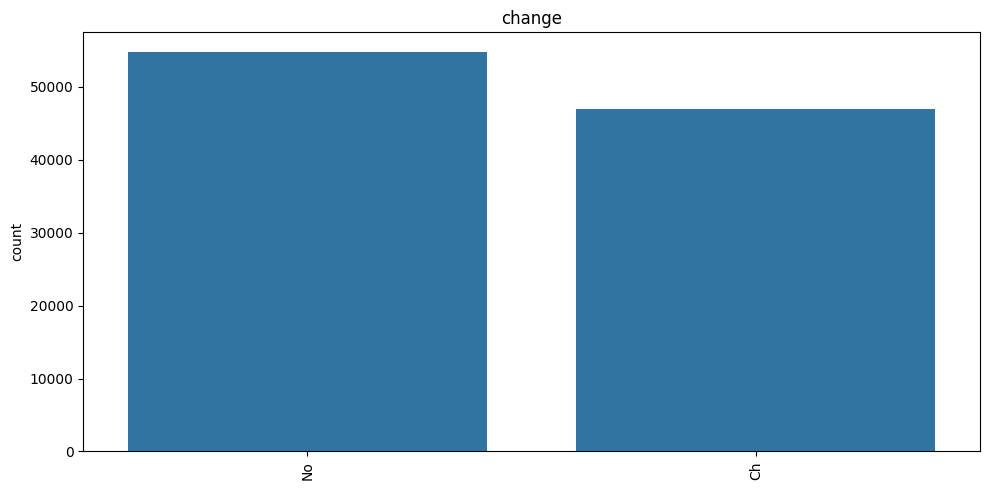

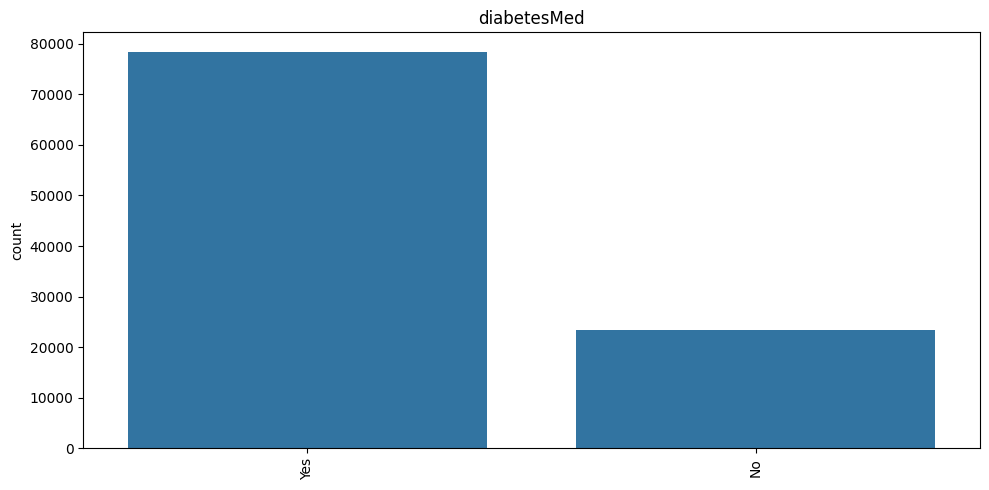

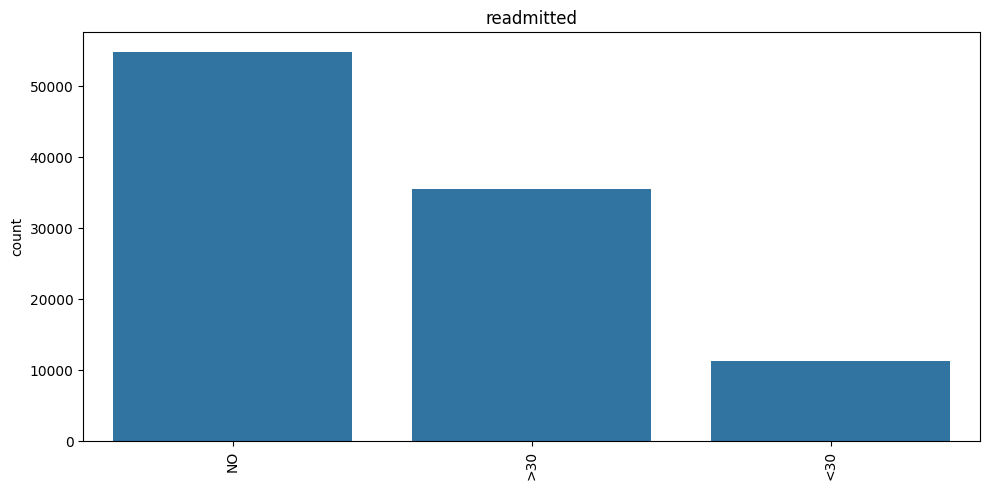

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = ['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id',
        'admission_source_id', 'payer_code', 'num_lab_procedures',
        'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
        'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
        'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
        'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin',
        'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone',
        'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

for col in cols:
    if col == 'admission_type_id' or col == 'admission_source_id':
        plt.figure(figsize=(12, 10))
    else: 
        plt.figure(figsize=(10, 5))
    if col == 'num_lab_procedures':
        sns.histplot(df["num_lab_procedures"], bins=30)
        plt.xlabel("Number of lab procedures")
        plt.ylabel("Number of encounters")
        plt.show()
    else:
        sns.countplot(data=df, x=col, order=df[col].value_counts().index)
        plt.title(col)
        plt.xlabel('')
        plt.xticks(rotation=90)
        plt.tight_layout()
        plt.show()


### Merging of categories within variables
Here I will merge the smallest categories together so that the data will be more balanced.

The resulting variables are called:
- `age` → `age_grouped`
- `admission_source_id` → `admission_source_grouped`
- `admission_type_id` → `admission_type_grouped`

As is visible in the graphs, admission_source_grouped and admission_type_grouped have missing values called `Unknown`, although it is not noted in the dataset as missing values

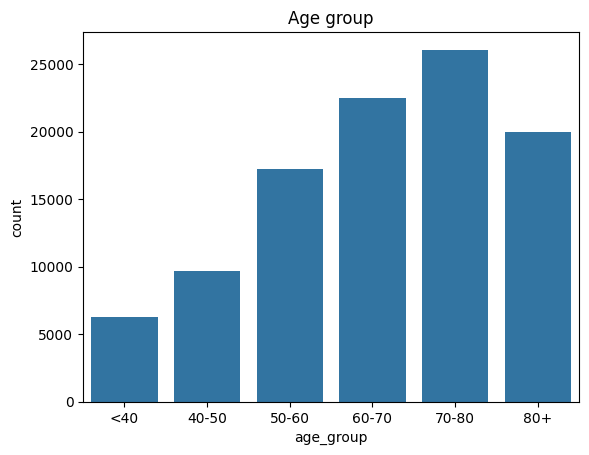

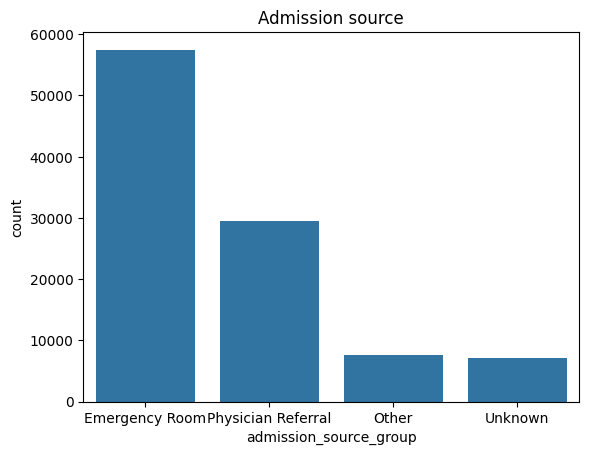

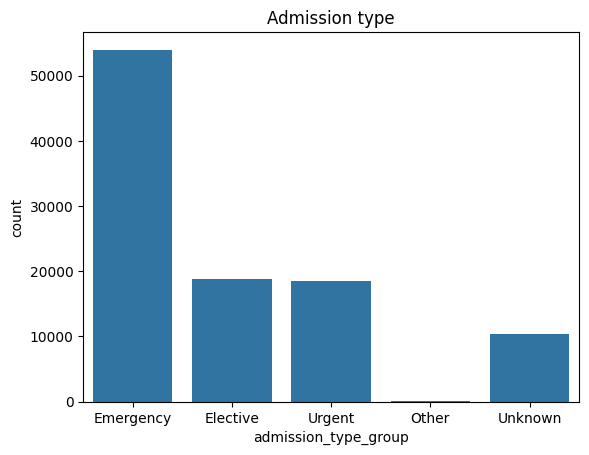

In [ ]:
# Age groups
age_groups = {
    "[0-10)": "<40", "[10-20)": "<40", "[20-30)": "<40",
    "[30-40)": "<40", "[40-50)": "40-50", "[50-60)": "50-60",
    "[60-70)": "60-70", "[70-80)": "70-80",
    "[80-90)": "80+", "[90-100)": "80+",
}
df["age_grouped"] = df["age"].map(age_groups)

# Plot, sorted by age
order = ["<40", "40-50", "50-60", "60-70", "70-80", "80+"]
sns.countplot(data=df, x="age_grouped", order=order)
plt.title("Age grouped")
plt.show()

# Admission source
source_groups = {
    "Emergency Room": "Emergency Room",
    "Physician Referral": "Physician Referral",
    "Transfer from a hospital": "Other",
    "Transfer from another health care facility": "Other",
    "Clinic Referral": "Other",
    "Transfer from a Skilled Nursing Facility (SNF)": "Other",
    "HMO Referral": "Other",
    "Court/Law Enforcement": "Other",
    "Transfer from hospital inpt/same fac reslt in a sep claim": "Other",
    "Transfer from critial access hospital": "Other",
    "Extramural Birth": "Other",
    "Normal Delivery": "Other",
    "Transfer from Ambulatory Surgery Center": "Other",
    "Sick Baby": "Other",
    "Premature Delivery": "Other",
    "Transfer From Another Home Health Agency": "Other",
    "Readmission to Same Home Health Agency": "Other",
    "Born inside this hospital": "Other",
    "Born outside this hospital": "Other",
    "Transfer from Hospice": "Other",
    "Not Mapped": "Unknown",
    "Not Available": "Unknown",
    "Unknown/Invalid": "Unknown",
    "NULL": "Unknown",
}
source_groups.update({" " + key: value for key, value in source_groups.items()})

df["admission_source_grouped"] = (
    df["admission_source_id"].map(source_groups).fillna("Unknown")
)

order = ["Emergency Room", "Physician Referral", "Other", "Unknown"]
sns.countplot(data=df, x="admission_source_grouped", order=order)
plt.title("Admission source")
plt.show()

# Admission type
type_groups = {
    "Emergency": "Emergency",
    "Elective": "Elective",
    "Urgent": "Urgent",
    "Trauma Center": "Other",
    "Newborn": "Other",
    "Not Available": "Unknown",
    "Not Mapped": "Unknown",
}
type_groups.update({" " + key: value for key, value in source_groups.items()})

df["admission_type_grouped"] = df["admission_type_id"].map(type_groups).fillna("Unknown")

order = ["Emergency", "Elective", "Urgent", "Other", "Unknown"]
sns.countplot(data=df, x="admission_type_grouped", order=order)
plt.title("Admission type")
plt.show()

### Bivariate plots

<h1><u> Encoding </u></h1>
<h3>Encoding the 'gender', 'age' and 'admission_type_id'</h3>

<i>What is it for?</i> To turn text into numbers for the models to be able to work.





In [ ]:


df['gender'] = df['gender'].map({
    'Male': 0,
    'Female': 1
})


df['admission_type_id'] = df['admission_type_id'].replace({
    1: 'Emergency',
    2: 'Urgent',
    3: 'Elective',
    4: 'Newborn',
    5: 'unknown',
    6: 'unknown',
    8: 'unknown',
    7: 'Trauma Center'
})

<h3> admission_source_id encoding </h3>
The numbered values were changed into their description, so that one hot encoding could group them easily. Any value that did not have a count of over 100 went into the other category.

In [ ]:
print(df['admission_source_id'].unique())
print(df['admission_source_id'].value_counts)

df['admission_source_id'] = df['admission_source_id'].replace({
    1: 'Physician Referral',
    2: 'Clinic Referral',
    3: 'HMO Referral',
    4: 'Transfer from a hospital',
    5: 'Transfer from a Skilled Nursing Facility (SNF)',
    6: 'Transfer from another health care facility',
    7: 'Emergency Room',
    8: 'other',
    9: 'unknown',
    10: 'other',
    11: 'other',
    12: 'Premature Delivery',
    13: 'other',
    14: 'other',
    15: 'unknown',
    16: 'unknown',
    17: 'unknown',
    18: 'Transfer From Another Home Health Agency',
    19: 'Readmission to Same Home Health Agency',
    20: 'unknown',
    21: 'unknown',
    22: 'other',
    23: 'Born inside this hopsital',
    24: 'Born outside this hospital',
    25: 'other',
    26: 'Transfer from Hospice'

})

[ 1  7  2  4  5  6 20  3 17  8  9 14 10 22 11 25 13]
<bound method IndexOpsMixin.value_counts of 0         1
1         7
2         7
3         7
4         7
         ..
101761    7
101762    5
101763    7
101764    7
101765    7
Name: admission_source_id, Length: 101766, dtype: int64>


<h3>Encoding medical_specialty</h3>

In [ ]:
print(df['medical_specialty'].unique())
print(df['medical_specialty'].value_counts)

df['medical_specialty'] = df['medical_specialty'].fillna('unknown')
df['medical_specialty'] = df['medical_specialty'].replace({
    'Surgery-General': 'surgery',
    'Surgery-Cardiovascular/Thoracic': 'surgery',
    'Surgery-Neuro': 'surgery',
    'Surgery-Colon&Rectal': 'surgery',
    'Surgery-Thoracic': 'surgery',
    'Surgery-Vascular': 'surgery',
    'Surgery-Plastic': 'surgery',
    'Surgery-Cardiovascular': 'surgery',
    'Surgery-Maxillofacial': 'surgery',
    'Surgery-Pediatric': 'surgery',
    'Surgery-PlasticwithinHeadandNeck': 'surgery'
})


<StringArray>
[            'Pediatrics-Endocrinology',
                                    nan,
                     'InternalMedicine',
               'Family/GeneralPractice',
                           'Cardiology',
                      'Surgery-General',
                          'Orthopedics',
                     'Gastroenterology',
      'Surgery-Cardiovascular/Thoracic',
                           'Nephrology',
           'Orthopedics-Reconstructive',
                           'Psychiatry',
                     'Emergency/Trauma',
                          'Pulmonology',
                        'Surgery-Neuro',
 'Obsterics&Gynecology-GynecologicOnco',
              'ObstetricsandGynecology',
                           'Pediatrics',
                  'Hematology/Oncology',
                       'Otolaryngology',
                 'Surgery-Colon&Rectal',
              'Pediatrics-CriticalCare',
                        'Endocrinology',
                              'Urology',
  

In [ ]:
categorical_columns = ['age', 'admission_type_id', 'admission_source_id']
diabetic_data_encoded = pd.get_dummies(
    df,
    columns = categorical_columns,
    dtype=int,
    drop_first=True
)
print(diabetic_data_encoded.head())

   encounter_id  patient_nbr             race  gender weight  \
0       2278392      8222157        Caucasian     1.0    NaN   
1        149190     55629189        Caucasian     1.0    NaN   
2         64410     86047875  AfricanAmerican     1.0    NaN   
3        500364     82442376        Caucasian     0.0    NaN   
4         16680     42519267        Caucasian     0.0    NaN   

   discharge_disposition_id  time_in_hospital payer_code  \
0                        25                 1        NaN   
1                         1                 3        NaN   
2                         1                 2        NaN   
3                         1                 2        NaN   
4                         1                 1        NaN   

          medical_specialty  num_lab_procedures  ...  \
0  Pediatrics-Endocrinology                  41  ...   
1                   unknown                  59  ...   
2                   unknown                  11  ...   
3                   unknown   

In [ ]:
print(df['gender'].value_counts())
df.groupby('gender')['time_in_hospital'].mean()
female = df[df['gender'] == 'Female'].copy()

female.info

gender
1.0    54708
0.0    47055
Name: count, dtype: int64


<bound method DataFrame.info of Empty DataFrame
Columns: [encounter_id, patient_nbr, race, gender, weight, discharge_disposition_id, time_in_hospital, payer_code, medical_specialty, num_lab_procedures, num_procedures, num_medications, number_outpatient, number_emergency, number_inpatient, diag_1, diag_2, diag_3, number_diagnoses, max_glu_serum, A1Cresult, metformin, repaglinide, nateglinide, chlorpropamide, glimepiride, acetohexamide, glipizide, glyburide, tolbutamide, pioglitazone, rosiglitazone, acarbose, miglitol, troglitazone, tolazamide, examide, citoglipton, insulin, glyburide-metformin, glipizide-metformin, glimepiride-pioglitazone, metformin-rosiglitazone, metformin-pioglitazone, change, diabetesMed, readmitted, age_[10-20), age_[20-30), age_[30-40), age_[40-50), age_[50-60), age_[60-70), age_[70-80), age_[80-90), age_[90-100), admission_type_id_Emergency, admission_type_id_Newborn, admission_type_id_Trauma Center, admission_type_id_Urgent, admission_type_id_unknown, admission_

In [ ]:
print(df['gender'].value_counts())
df.groupby('gender')['time_in_hospital'].mean()
male = df[df['gender'] == 'Male'].copy()

male.info

gender
1.0    54708
0.0    47055
Name: count, dtype: int64


<bound method DataFrame.info of Empty DataFrame
Columns: [encounter_id, patient_nbr, race, gender, weight, discharge_disposition_id, time_in_hospital, payer_code, medical_specialty, num_lab_procedures, num_procedures, num_medications, number_outpatient, number_emergency, number_inpatient, diag_1, diag_2, diag_3, number_diagnoses, max_glu_serum, A1Cresult, metformin, repaglinide, nateglinide, chlorpropamide, glimepiride, acetohexamide, glipizide, glyburide, tolbutamide, pioglitazone, rosiglitazone, acarbose, miglitol, troglitazone, tolazamide, examide, citoglipton, insulin, glyburide-metformin, glipizide-metformin, glimepiride-pioglitazone, metformin-rosiglitazone, metformin-pioglitazone, change, diabetesMed, readmitted, age_[10-20), age_[20-30), age_[30-40), age_[40-50), age_[50-60), age_[60-70), age_[70-80), age_[80-90), age_[90-100), admission_type_id_Emergency, admission_type_id_Newborn, admission_type_id_Trauma Center, admission_type_id_Urgent, admission_type_id_unknown, admission_

In [ ]:
#Admission type id -> Time in hospital
admission_type_means = df.groupby(['admission_type_id'])['time_in_hospital'].mean()

#Admissionn source id -> Time in hospital
admission_source_means = df.groupby(['admission_source_id'])['time_in_hospital'].mean()

#Replacing the admission type id and admission source id with their descriptions
admission_type_means.index = admission_type_means.index.map(admission_type_descriptions)
admission_source_means.index = admission_source_means.index.map(admission_source_descriptions)

print(admission_type_means)
print(admission_source_means)

#Grouping admission type id with admission source id
admission_type_source_means = df.groupby(['admission_type_id', 'admission_source_id'])['time_in_hospital'].mean()
admission_type_source_means.index = admission_type_source_means.index.map(lambda x: (admission_type_descriptions.get(x[0]), admission_source_descriptions.get(x[1])))

print(admission_type_source_means)


KeyError: 'admission_type_id'

In [16]:
#ANOVA test to see what factors have a significant effect on the time in hospital
import statsmodels.api as sm

model = sm.OLS(diabetic_data_2['time_in_hospital'], sm.add_constant(diabetic_data_2[['admission_type_id', 'admission_source_id']])).fit()

print(model.summary())

#Determining significant factors based on p-values
significant_factors = model.pvalues[model.pvalues < 0.05].index
print(significant_factors)


ModuleNotFoundError: No module named 'statsmodels'

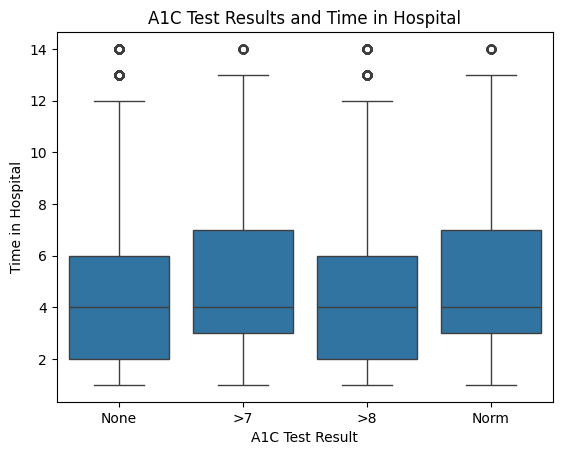

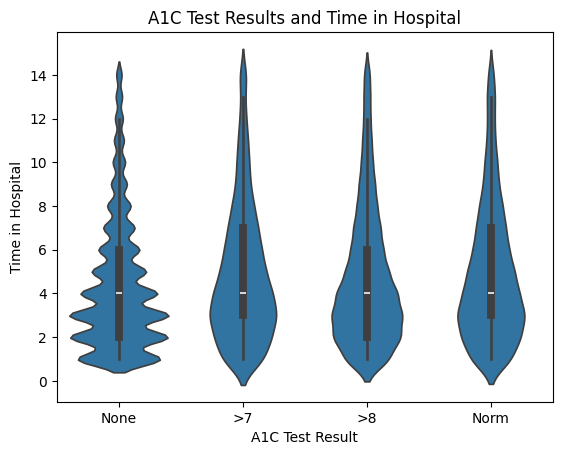

In [ ]:
#Generating a plot for A1C tests and time in hospital
sns.boxplot(data=df, x='A1Cresult', y='time_in_hospital')
plt.title('A1C Test Results and Time in Hospital')
plt.xlabel('A1C Test Result')
plt.ylabel('Time in Hospital')

#Generating a violin plot
plt.figure()
sns.violinplot(data=df, x='A1Cresult', y='time_in_hospital')
plt.title('A1C Test Results and Time in Hospital')
plt.xlabel('A1C Test Result')
plt.ylabel('Time in Hospital')
plt.show()

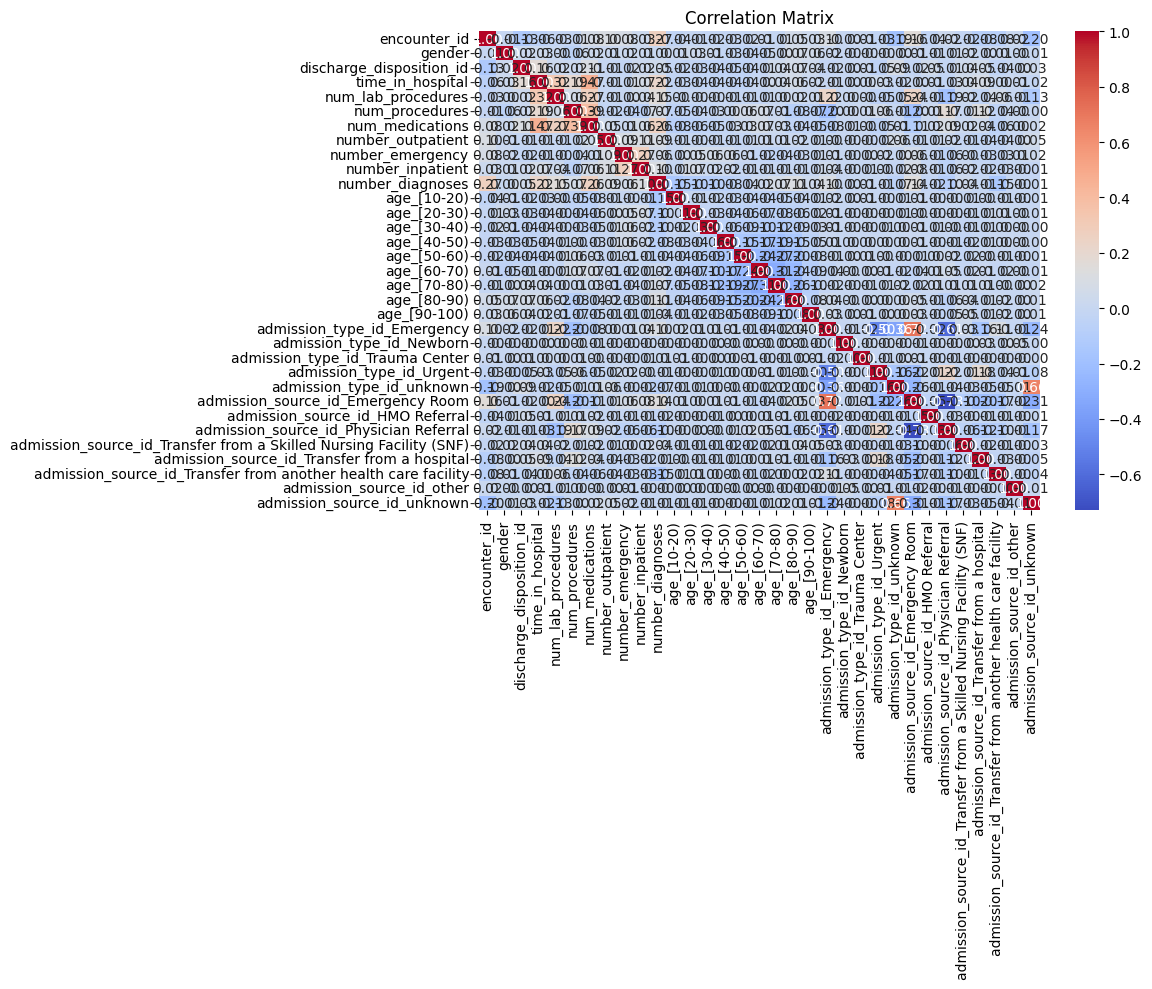

In [ ]:
#Correlation Matrix
plt.figure(figsize=(12,10))
numeric_data = df.select_dtypes(include='number').drop(columns='patient_nbr', errors='ignore')
correlation_matrix = numeric_data.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.savefig('correlation_matrix.png')


/var/folders/t2/z2d0j1ns56l8gkc11rwm53pw0000gn/T/ipykernel_38771/1168845369.py:6: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(8,4))


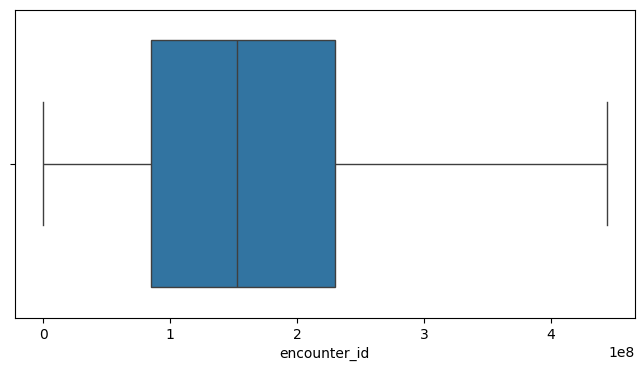

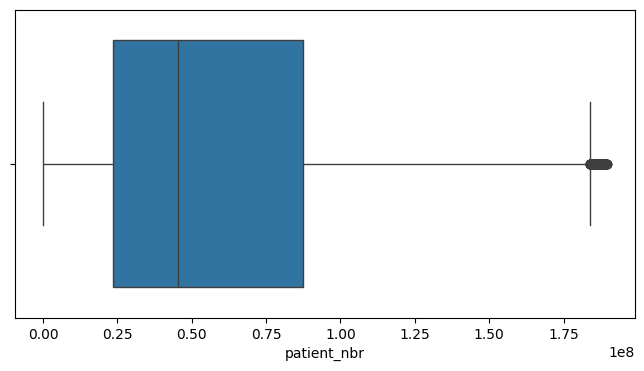

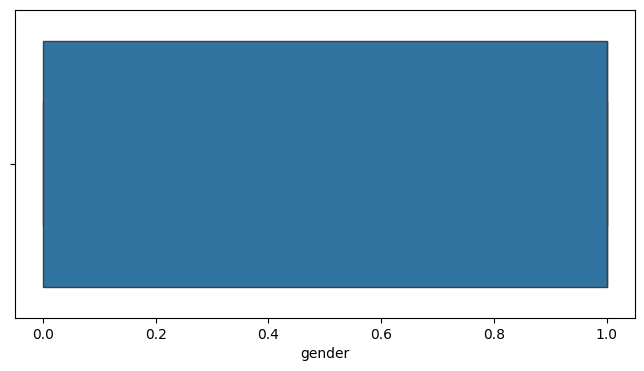

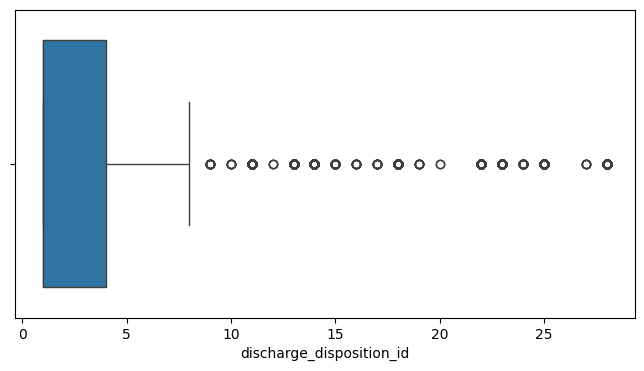

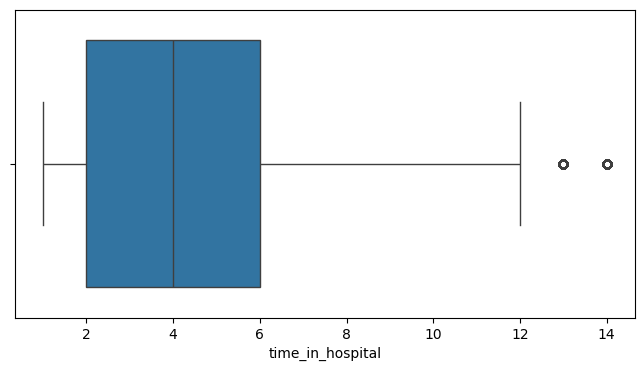

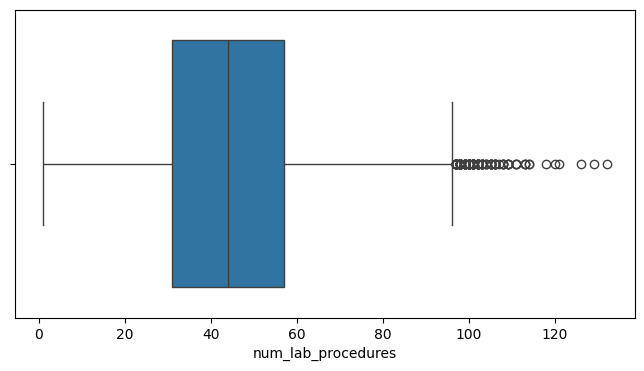

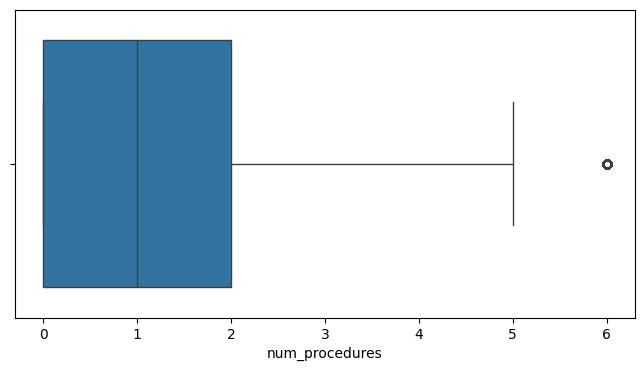

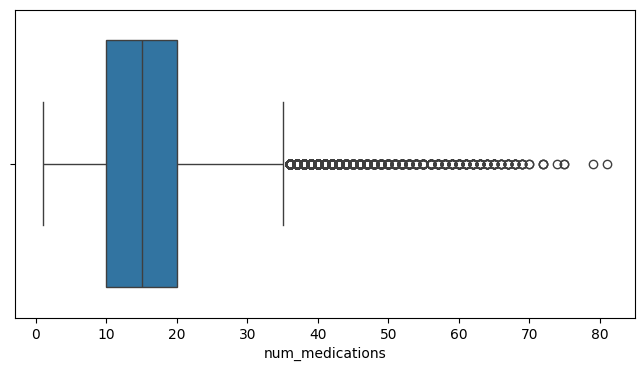

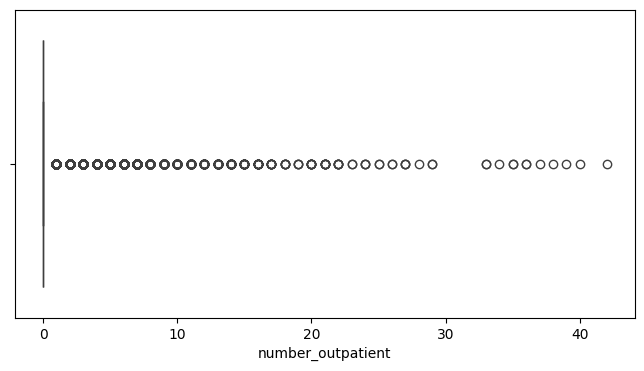

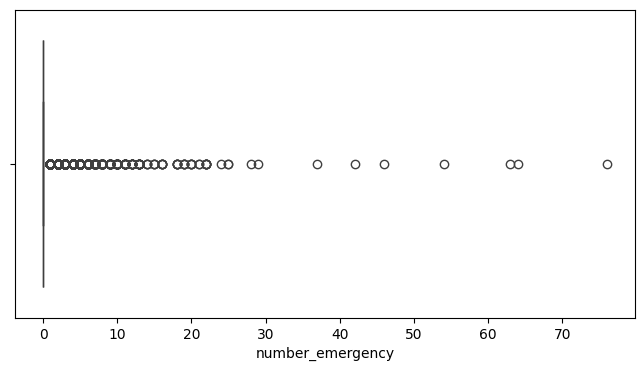

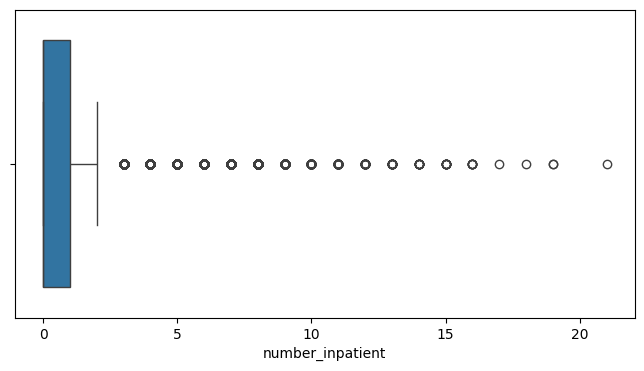

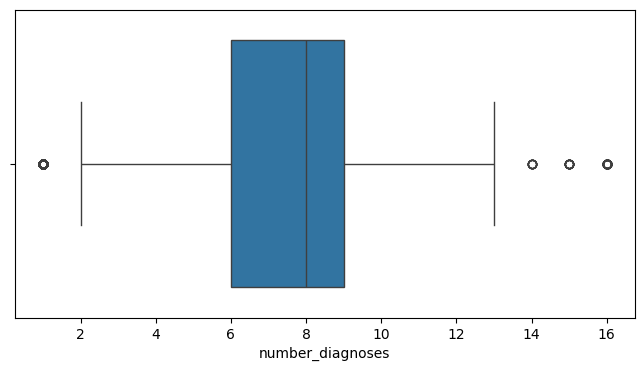

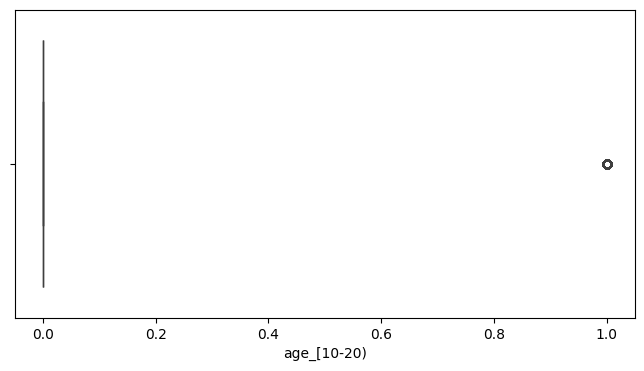

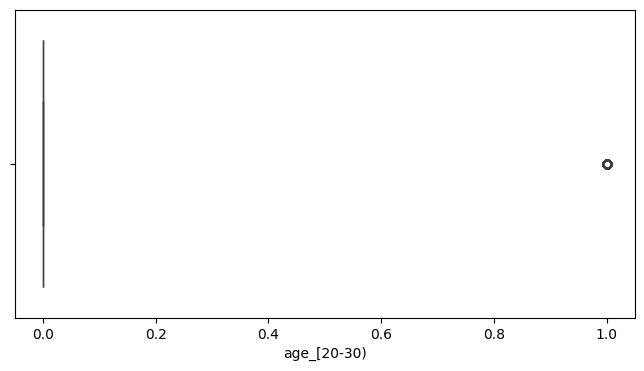

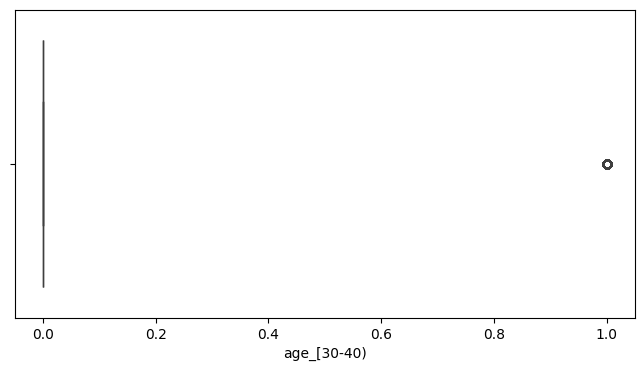

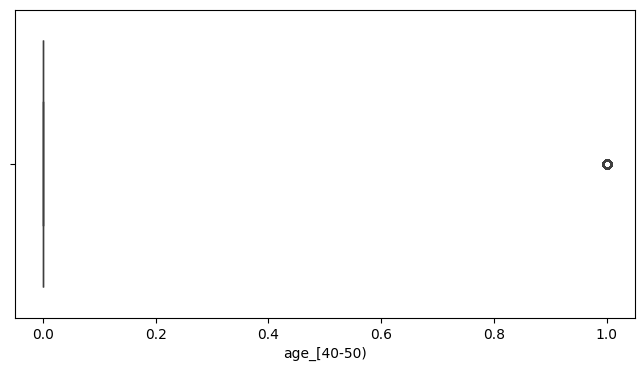

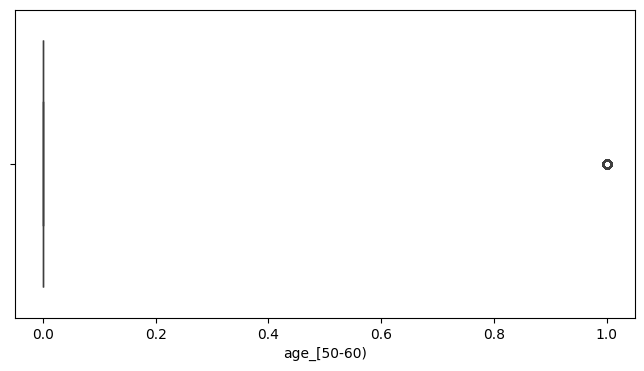

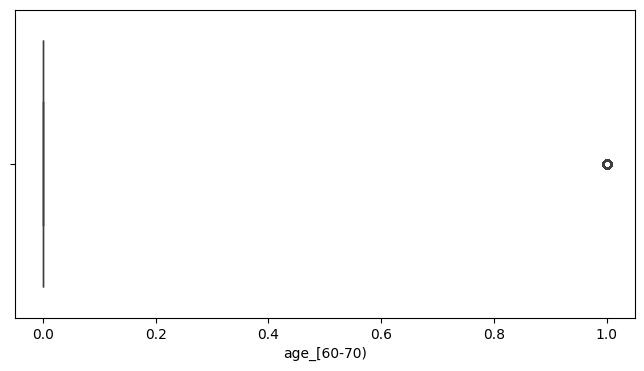

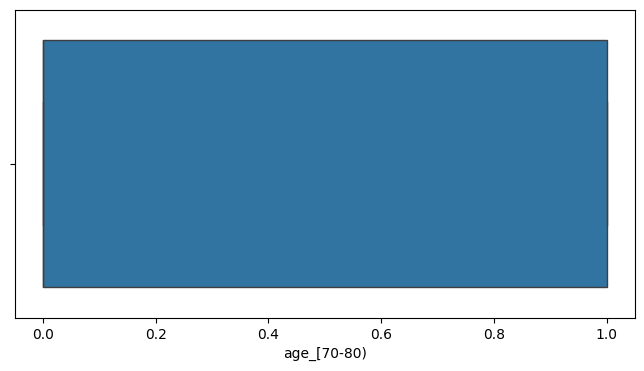

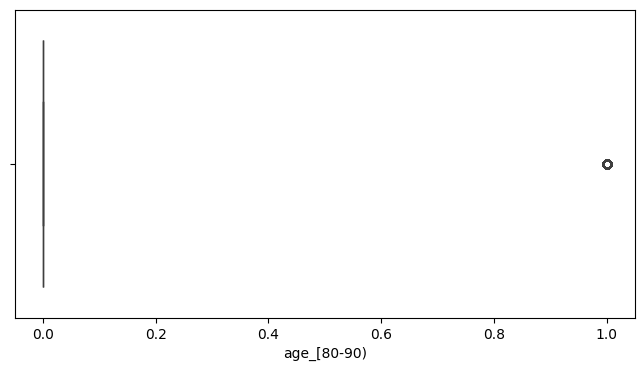

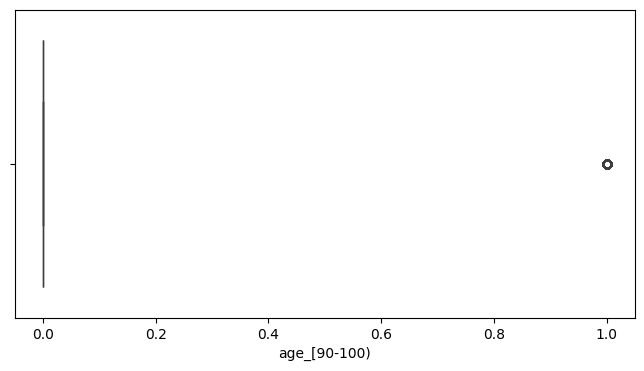

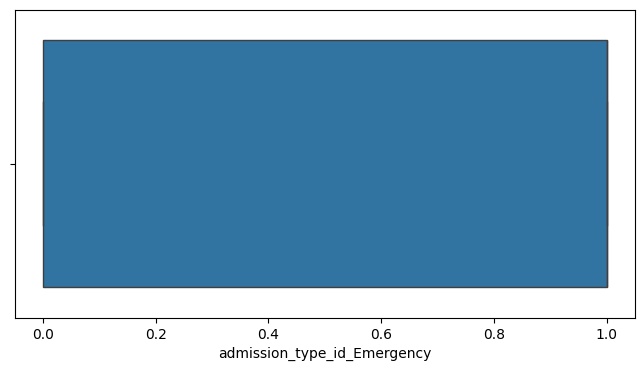

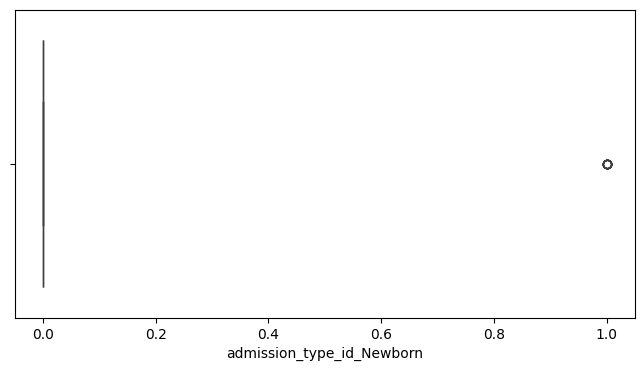

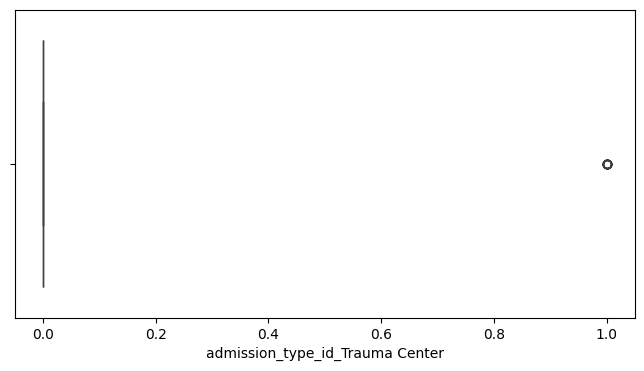

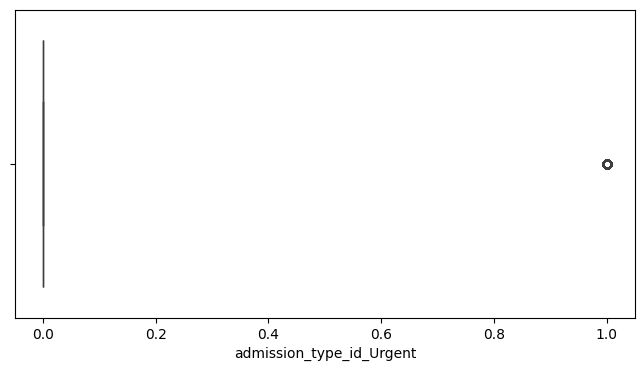

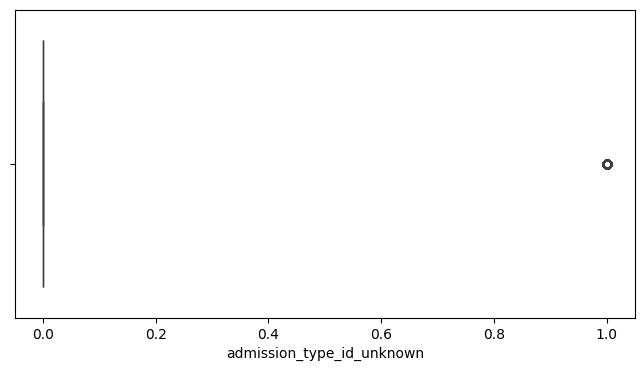

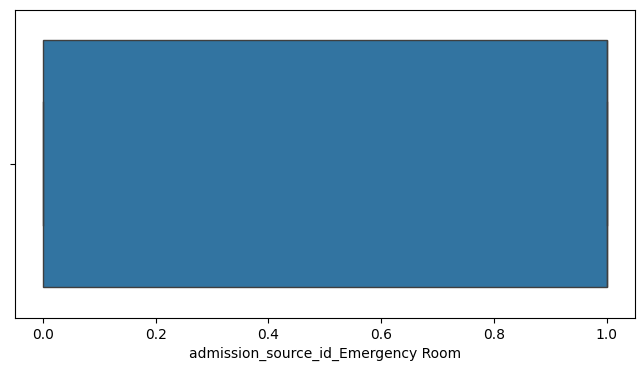

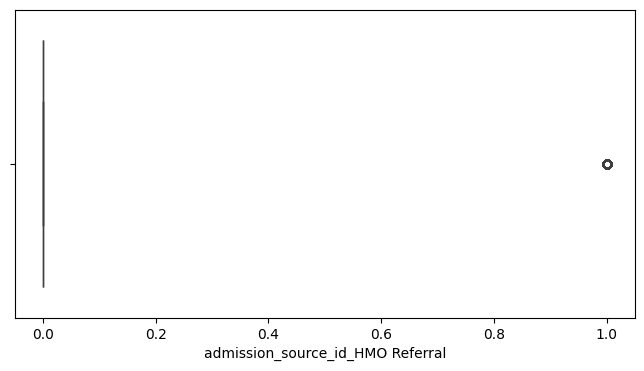

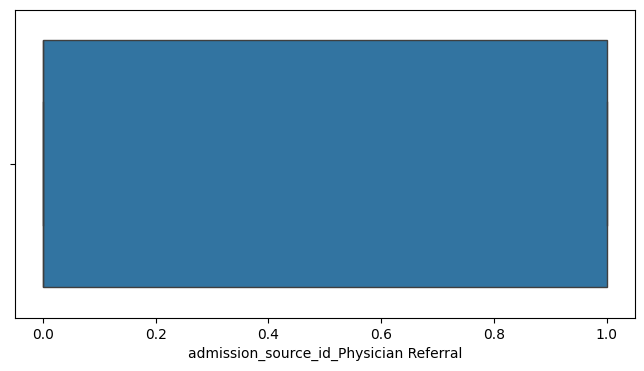

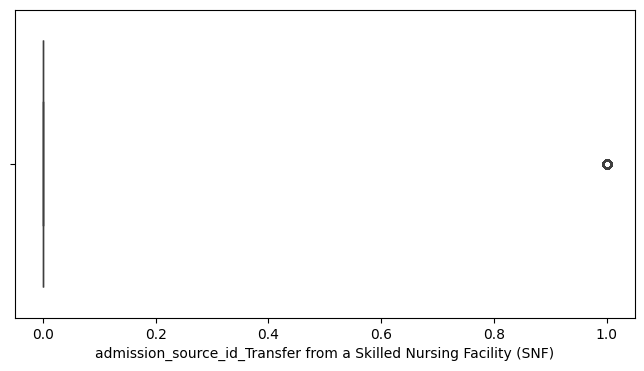

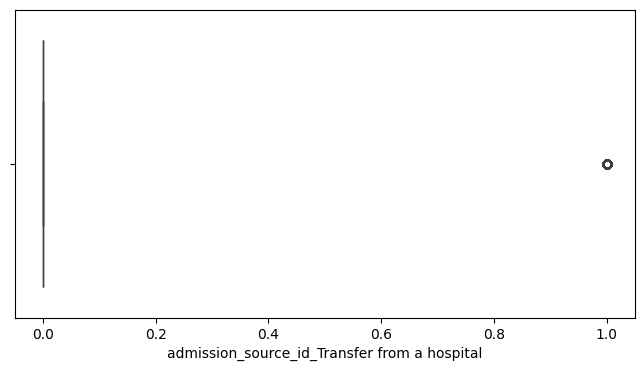

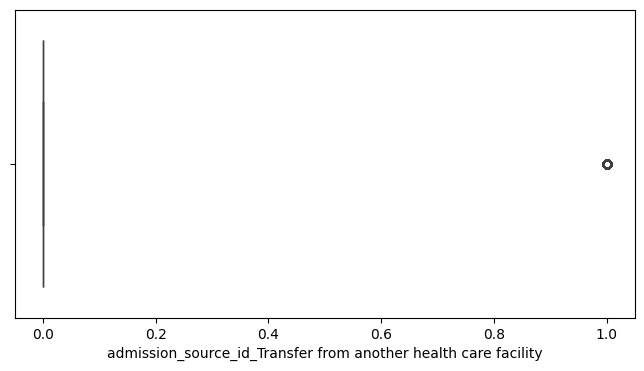

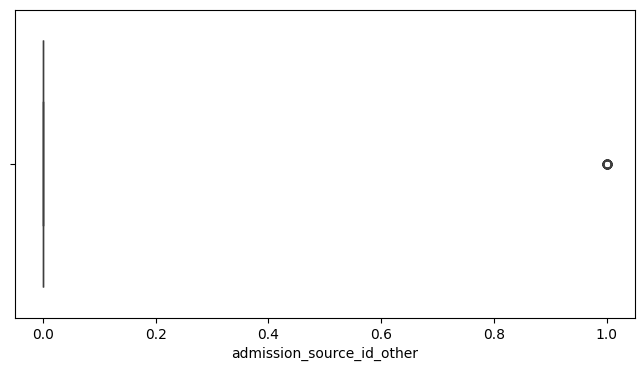

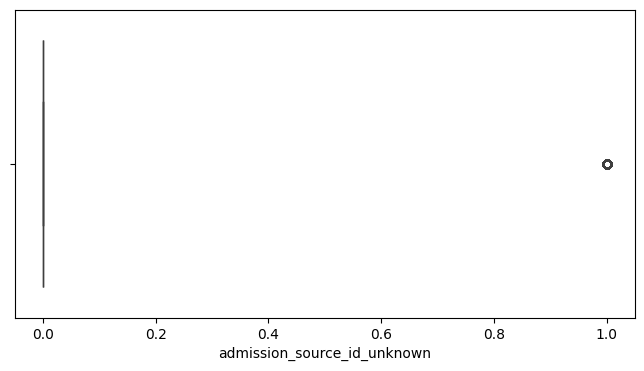

In [ ]:
numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns

for col in numerical_columns:
    plt.figure(figsize=(8,4))
    sns.boxplot(x=df[col])



<h1>Logistic Regression</h1>

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#Split the data
# Predict A1C result from time in hospital
X = df[['time_in_hospital']]
y = df['A1Cresult']

# Remove rows with missing target values
valid = y.notna()
X = X.loc[valid]
y = y.loc[valid]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize using training data only
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
#Time in hospital based on a1c result

#Standardize
scaler = StandardScaler()

#Create train model
sk_model = LogisticRegression(max_iter=1000)
sk_model.fit(X_train, y_train)

#Make predictions
y_pred = sk_model.predict(X_test)
y_prob = sk_model.predict_proba(X_test)[:, 1]

#Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred))

#Plot Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()



ImportError: sklearn._cyutility does not export expected C function slice_memviewslice